In [12]:
# Import all libraries required for the project.

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

%matplotlib inline

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

PyTorch version: 2.11.0+cpu
Device: cpu


In [13]:
# Define the paths of the three datasets.

load_path = r"Load_Forecasting.csv"
solar_path = r"Solar_Forecasting.csv"
wind_path = r"Wind_Forecasting.csv"

In [14]:
# Load the three datasets into Pandas DataFrames.

load_df = pd.read_csv(load_path)
solar_df = pd.read_csv(solar_path)
wind_df = pd.read_csv(wind_path)

In [15]:
# Convert the datetime column to Pandas datetime format.

load_df["Datetime_UTC"] = pd.to_datetime(load_df["Datetime_UTC"])
solar_df["Datetime_UTC"] = pd.to_datetime(solar_df["Datetime_UTC"])
wind_df["Datetime_UTC"] = pd.to_datetime(wind_df["Datetime_UTC"])

In [16]:
# Sort all datasets by timestamp and reset the index.

load_df = load_df.sort_values("Datetime_UTC").reset_index(drop=True)
solar_df = solar_df.sort_values("Datetime_UTC").reset_index(drop=True)
wind_df = wind_df.sort_values("Datetime_UTC").reset_index(drop=True)

In [17]:
# Display the basic information of all three datasets.

print("LOAD DATASET")
print("=" * 50)
print("Shape:", load_df.shape)
print("Columns:", load_df.columns.tolist())
display(load_df.head())

print("\nSOLAR DATASET")
print("=" * 50)
print("Shape:", solar_df.shape)
print("Columns:", solar_df.columns.tolist())
display(solar_df.head())

print("\nWIND DATASET")
print("=" * 50)
print("Shape:", wind_df.shape)
print("Columns:", wind_df.columns.tolist())
display(wind_df.head())

LOAD DATASET
Shape: (26297, 12)
Columns: ['Datetime_UTC', 'Load_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'IsWeekend', 'IsHoliday']


,Datetime_UTC,Load_MW,T2M,RH2M,WS10M,CLOUD_AMT,Hour,DayOfWeek,DayOfYear,Month,IsWeekend,IsHoliday
0,2023-01-01 07:00:00+00:00,35829.306163,11.32,69.29,5.05,2.37,7,6,1,1,1,1
1,2023-01-01 08:00:00+00:00,35245.390234,10.36,75.44,4.62,10.12,8,6,1,1,1,1
2,2023-01-01 09:00:00+00:00,34599.761810,9.76,79.94,4.48,17.85,9,6,1,1,1,1
3,2023-01-01 10:00:00+00:00,34227.151061,9.22,83.95,4.39,57.65,10,6,1,1,1,1
4,2023-01-01 11:00:00+00:00,34093.414143,8.69,87.17,4.19,99.70,11,6,1,1,1,1



SOLAR DATASET
Shape: (26297, 14)
Columns: ['Datetime_UTC', 'Solar_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'ALLSKY_KT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month']


,Datetime_UTC,Solar_MW,T2M,RH2M,WS10M,CLOUD_AMT,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,0.449746,11.32,69.29,5.05,2.37,0.0,0.0,0.0,NaN,7,6,1,1
1,2023-01-01 08:00:00+00:00,0.454733,10.36,75.44,4.62,10.12,0.0,0.0,0.0,NaN,8,6,1,1
2,2023-01-01 09:00:00+00:00,0.443528,9.76,79.94,4.48,17.85,0.0,0.0,0.0,NaN,9,6,1,1
3,2023-01-01 10:00:00+00:00,0.458567,9.22,83.95,4.39,57.65,0.0,0.0,0.0,NaN,10,6,1,1
4,2023-01-01 11:00:00+00:00,0.451126,8.69,87.17,4.19,99.70,0.0,0.0,0.0,NaN,11,6,1,1



WIND DATASET
Shape: (26297, 10)
Columns: ['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month']


,Datetime_UTC,Wind_MW,T2M,RH2M,WS10M,CLOUD_AMT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,21753.284477,11.32,69.29,5.05,2.37,7,6,1,1
1,2023-01-01 08:00:00+00:00,21570.395694,10.36,75.44,4.62,10.12,8,6,1,1
2,2023-01-01 09:00:00+00:00,21036.504013,9.76,79.94,4.48,17.85,9,6,1,1
3,2023-01-01 10:00:00+00:00,20595.481515,9.22,83.95,4.39,57.65,10,6,1,1
4,2023-01-01 11:00:00+00:00,20387.843555,8.69,87.17,4.19,99.70,11,6,1,1


In [18]:
# Check the time range covered by each dataset.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(f"{name}:")
    print("Start:", df["Datetime_UTC"].min())
    print("End  :", df["Datetime_UTC"].max())
    print()

Load:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00

Solar:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00

Wind:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00



In [19]:
# Check the number and percentage of missing values in each dataset.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(f"{name} missing values:")
    display(pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": df.isnull().mean() * 100
    }))
    print()

Load missing values:


,Missing Count,Missing Percentage
Datetime_UTC,0,0.0
Load_MW,0,0.0
T2M,0,0.0
RH2M,0,0.0
WS10M,0,0.0
CLOUD_AMT,0,0.0
Hour,0,0.0
DayOfWeek,0,0.0
DayOfYear,0,0.0
Month,0,0.0



Solar missing values:


,Missing Count,Missing Percentage
Datetime_UTC,0,0.000000
Solar_MW,0,0.000000
T2M,0,0.000000
RH2M,0,0.000000
WS10M,0,0.000000
CLOUD_AMT,0,0.000000
ALLSKY_SFC_SW_DWN,0,0.000000
ALLSKY_SFC_SW_DNI,0,0.000000
ALLSKY_SFC_SW_DIFF,0,0.000000
ALLSKY_KT,12505,47.552953



Wind missing values:


,Missing Count,Missing Percentage
Datetime_UTC,0,0.0
Wind_MW,0,0.0
T2M,0,0.0
RH2M,0,0.0
WS10M,0,0.0
CLOUD_AMT,0,0.0
Hour,0,0.0
DayOfWeek,0,0.0
DayOfYear,0,0.0
Month,0,0.0


In [20]:
# Check for duplicate rows and duplicate timestamps.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(name)
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate timestamps:", df["Datetime_UTC"].duplicated().sum())
    print()

Load
Duplicate rows: 0
Duplicate timestamps: 0

Solar
Duplicate rows: 0
Duplicate timestamps: 0

Wind
Duplicate rows: 0
Duplicate timestamps: 0



In [21]:
# Check whether the datasets contain continuous hourly timestamps.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    expected = pd.date_range(
        start=df["Datetime_UTC"].min(),
        end=df["Datetime_UTC"].max(),
        freq="h"
    )

    missing_timestamps = expected.difference(df["Datetime_UTC"])

    print(name)
    print("Expected timestamps:", len(expected))
    print("Actual timestamps  :", len(df))
    print("Missing timestamps :", len(missing_timestamps))
    print()

Load
Expected timestamps: 26297
Actual timestamps  : 26297
Missing timestamps : 0

Solar
Expected timestamps: 26297
Actual timestamps  : 26297
Missing timestamps : 0

Wind
Expected timestamps: 26297
Actual timestamps  : 26297
Missing timestamps : 0



In [22]:
# Create time-based features from the datetime column for EDA.

for df in [load_df, solar_df, wind_df]:
    df["Hour_Calc"] = df["Datetime_UTC"].dt.hour
    df["DayOfWeek_Calc"] = df["Datetime_UTC"].dt.dayofweek
    df["DayOfYear_Calc"] = df["Datetime_UTC"].dt.dayofyear
    df["Month_Calc"] = df["Datetime_UTC"].dt.month
    df["Year_Calc"] = df["Datetime_UTC"].dt.year

In [23]:
# Calculate the average target value for every hour of the day.

hourly_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("Hour_Calc")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("Hour_Calc")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("Hour_Calc")["Wind_MW"].mean()
})

display(hourly_pattern)

,Load_MW,Solar_MW,Wind_MW
Hour_Calc,,,
0,60003.199465,6173.533936,11741.277970
1,59113.524710,1886.701631,12489.867789
2,57997.122623,131.272923,13572.695826
3,56619.517314,2.481388,14789.710789
4,54373.121053,1.168896,15631.040170
5,51682.695205,0.642824,15982.580581
6,49195.140770,0.607701,15998.770323
7,47300.188044,0.504021,15702.275586
8,46015.289529,0.489495,15245.156893


In [24]:
# Convert UTC timestamps to Texas Central local time for all datasets.

load_df["Datetime_Local"] = load_df["Datetime_UTC"].dt.tz_convert("America/Chicago")
solar_df["Datetime_Local"] = solar_df["Datetime_UTC"].dt.tz_convert("America/Chicago")
wind_df["Datetime_Local"] = wind_df["Datetime_UTC"].dt.tz_convert("America/Chicago")

In [25]:
# Remove the previously created time features that were calculated from UTC time.

old_time_columns = [
    "Hour_Calc",
    "DayOfWeek_Calc",
    "DayOfYear_Calc",
    "Month_Calc",
    "Year_Calc"
]

for df in [load_df, solar_df, wind_df]:
    df.drop(
        columns=[col for col in old_time_columns if col in df.columns],
        inplace=True
    )

In [26]:
# Create the same calendar features from Texas local time for all datasets.

for df in [load_df, solar_df, wind_df]:
    df["Hour"] = df["Datetime_Local"].dt.hour
    df["DayOfWeek"] = df["Datetime_Local"].dt.dayofweek
    df["DayOfYear"] = df["Datetime_Local"].dt.dayofyear
    df["Month"] = df["Datetime_Local"].dt.month
    df["Year"] = df["Datetime_Local"].dt.year

In [27]:
# Create a readable day-of-week column for EDA.

day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

for df in [load_df, solar_df, wind_df]:
    df["DayName"] = df["DayOfWeek"].map(day_names)

In [28]:
# Compare UTC and Texas local timestamps for all datasets.

print("LOAD")
display(load_df[["Datetime_UTC", "Datetime_Local"]].head())

print("\nSOLAR")
display(solar_df[["Datetime_UTC", "Datetime_Local"]].head())

print("\nWIND")
display(wind_df[["Datetime_UTC", "Datetime_Local"]].head())

LOAD


,Datetime_UTC,Datetime_Local
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00



SOLAR


,Datetime_UTC,Datetime_Local
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00



WIND


,Datetime_UTC,Datetime_Local
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00


In [29]:
# Check the timezone offsets present in each dataset.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    offsets = df["Datetime_Local"].apply(
        lambda x: str(x.utcoffset())
    ).value_counts()

    print(f"\n{name}")
    display(offsets)


Load


Datetime_Local
-1 day, 19:00:00    17133
-1 day, 18:00:00     9164
Name: count, dtype: int64


Solar


Datetime_Local
-1 day, 19:00:00    17133
-1 day, 18:00:00     9164
Name: count, dtype: int64


Wind


Datetime_Local
-1 day, 19:00:00    17133
-1 day, 18:00:00     9164
Name: count, dtype: int64

In [30]:
# Display the local-time features for all three datasets.

columns = [
    "Datetime_UTC",
    "Datetime_Local",
    "Hour",
    "DayOfWeek",
    "DayName",
    "DayOfYear",
    "Month",
    "Year"
]

print("LOAD")
display(load_df[columns].head())

print("\nSOLAR")
display(solar_df[columns].head())

print("\nWIND")
display(wind_df[columns].head())

LOAD


,Datetime_UTC,Datetime_Local,Hour,DayOfWeek,DayName,DayOfYear,Month,Year
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,1,6,Sunday,1,1,2023
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,2,6,Sunday,1,1,2023
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,3,6,Sunday,1,1,2023
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,4,6,Sunday,1,1,2023
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,5,6,Sunday,1,1,2023



SOLAR


,Datetime_UTC,Datetime_Local,Hour,DayOfWeek,DayName,DayOfYear,Month,Year
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,1,6,Sunday,1,1,2023
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,2,6,Sunday,1,1,2023
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,3,6,Sunday,1,1,2023
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,4,6,Sunday,1,1,2023
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,5,6,Sunday,1,1,2023



WIND


,Datetime_UTC,Datetime_Local,Hour,DayOfWeek,DayName,DayOfYear,Month,Year
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,1,6,Sunday,1,1,2023
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,2,6,Sunday,1,1,2023
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,3,6,Sunday,1,1,2023
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,4,6,Sunday,1,1,2023
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,5,6,Sunday,1,1,2023


In [31]:
# Check the UTC and local time ranges for all datasets.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(name)
    print("UTC start   :", df["Datetime_UTC"].min())
    print("Local start :", df["Datetime_Local"].min())
    print("UTC end     :", df["Datetime_UTC"].max())
    print("Local end   :", df["Datetime_Local"].max())
    print()

Load
UTC start   : 2023-01-01 07:00:00+00:00
Local start : 2023-01-01 01:00:00-06:00
UTC end     : 2025-12-31 23:00:00+00:00
Local end   : 2025-12-31 17:00:00-06:00

Solar
UTC start   : 2023-01-01 07:00:00+00:00
Local start : 2023-01-01 01:00:00-06:00
UTC end     : 2025-12-31 23:00:00+00:00
Local end   : 2025-12-31 17:00:00-06:00

Wind
UTC start   : 2023-01-01 07:00:00+00:00
Local start : 2023-01-01 01:00:00-06:00
UTC end     : 2025-12-31 23:00:00+00:00
Local end   : 2025-12-31 17:00:00-06:00



In [32]:
# Verify that the original UTC timeline remains continuous after adding local time.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    utc_differences = df["Datetime_UTC"].diff().dropna()

    print(name)
    print("Unique UTC intervals:")
    print(utc_differences.value_counts())
    print()

Load
Unique UTC intervals:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64

Solar
Unique UTC intervals:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64

Wind
Unique UTC intervals:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64



In [33]:
# Calculate average hourly behavior using the same Texas local-time definition for all datasets.

hourly_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("Hour")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("Hour")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("Hour")["Wind_MW"].mean()
})

display(hourly_pattern)

,Load_MW,Solar_MW,Wind_MW
Hour,,,
0,51075.981899,0.624815,16006.965176
1,48680.807020,0.598393,15955.389438
2,47039.960158,0.468558,15631.339853
3,45870.485544,0.492793,15157.181878
4,45210.314821,0.480216,14626.903485
5,45180.369909,0.659464,14094.680861
6,46125.446044,0.611187,13640.167925
7,47847.713970,20.935117,13202.398001
8,48955.418304,1291.238558,12620.304284


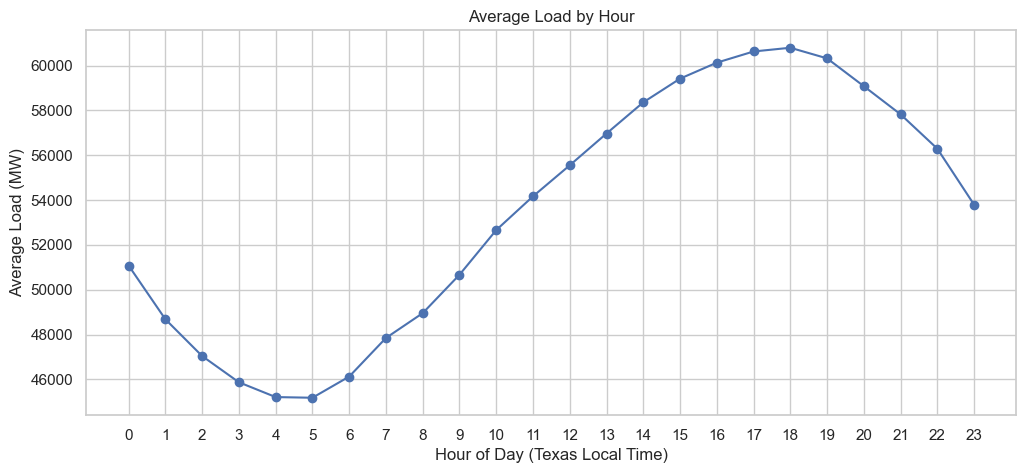

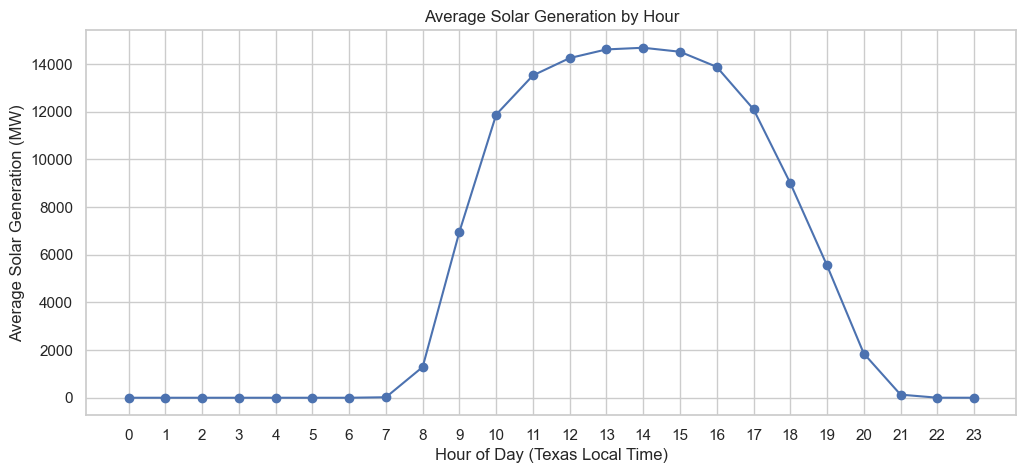

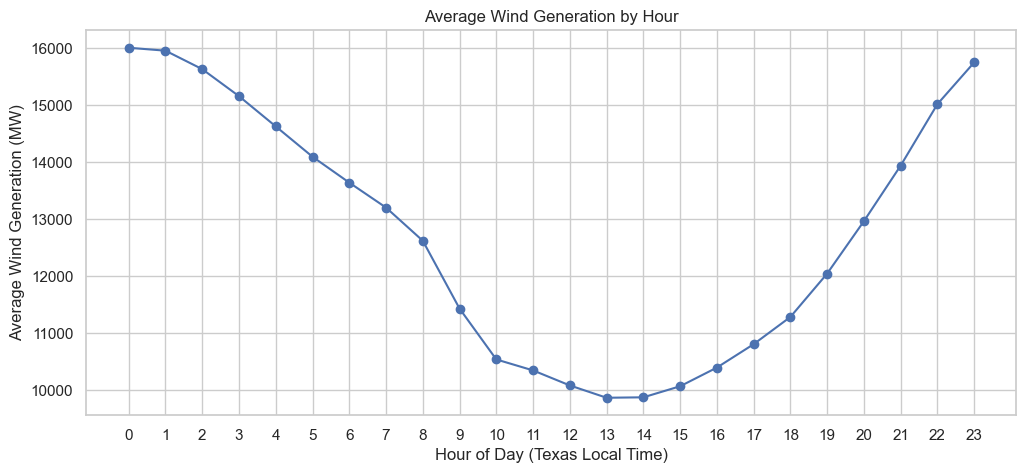

In [34]:
# Plot the average daily pattern of load, solar, and wind using Texas local time.

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["Load_MW"],
    marker="o"
)

plt.xlabel("Hour of Day (Texas Local Time)")
plt.ylabel("Average Load (MW)")
plt.title("Average Load by Hour")
plt.xticks(range(24))

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["Solar_MW"],
    marker="o"
)

plt.xlabel("Hour of Day (Texas Local Time)")
plt.ylabel("Average Solar Generation (MW)")
plt.title("Average Solar Generation by Hour")
plt.xticks(range(24))

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["Wind_MW"],
    marker="o"
)

plt.xlabel("Hour of Day (Texas Local Time)")
plt.ylabel("Average Wind Generation (MW)")
plt.title("Average Wind Generation by Hour")
plt.xticks(range(24))

plt.show()

In [35]:
# Calculate average generation/load for each day of the week.

weekday_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("DayOfWeek")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("DayOfWeek")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("DayOfWeek")["Wind_MW"].mean()
})

weekday_pattern.index = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

display(weekday_pattern)

,Load_MW,Solar_MW,Wind_MW
Monday,53980.155322,5650.169632,12418.394192
Tuesday,54129.842418,5664.726866,12672.682607
Wednesday,53981.356762,5551.232000,12629.239719
Thursday,53955.551062,5612.802764,12300.306427
Friday,53950.533833,5604.212408,13061.859699
Saturday,52348.440431,5506.639529,13134.118329
Sunday,51752.565217,5574.671956,12839.427665


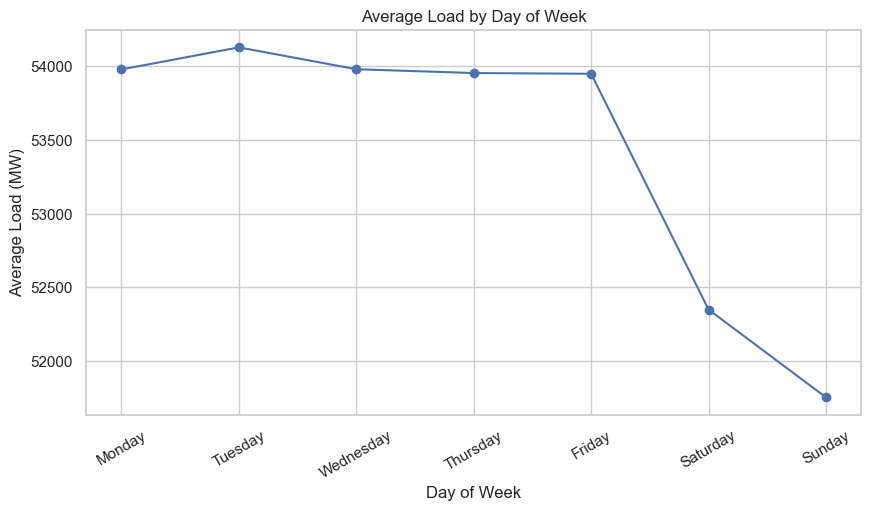

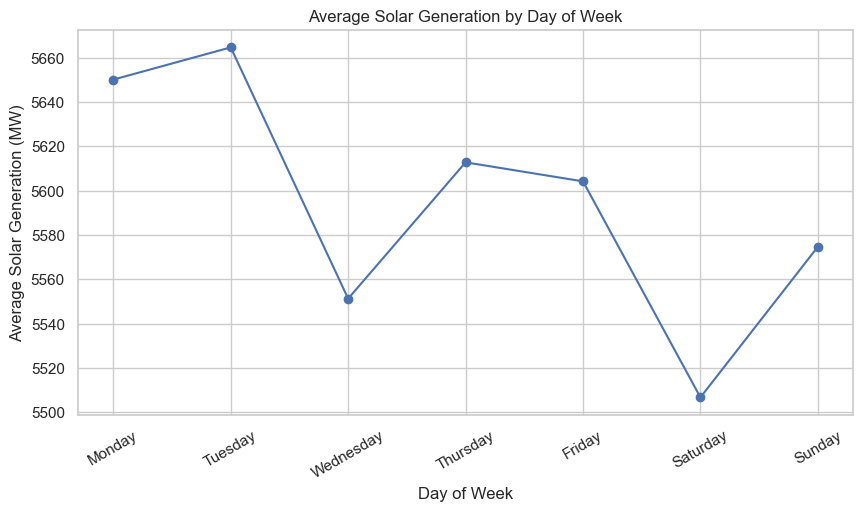

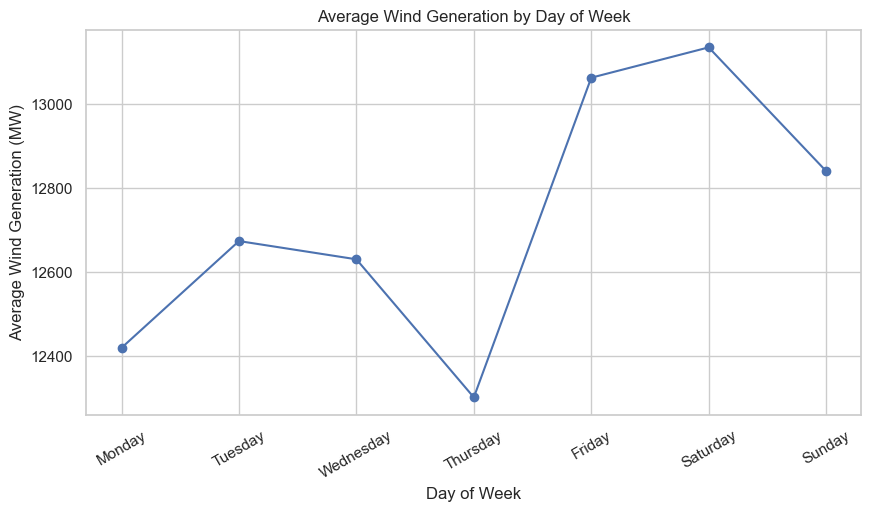

In [36]:
# Plot the average behavior for each day of the week.

plt.figure(figsize=(10, 5))

plt.plot(
    weekday_pattern.index,
    weekday_pattern["Load_MW"],
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Load (MW)")
plt.title("Average Load by Day of Week")
plt.xticks(rotation=30)

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    weekday_pattern.index,
    weekday_pattern["Solar_MW"],
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Solar Generation (MW)")
plt.title("Average Solar Generation by Day of Week")
plt.xticks(rotation=30)

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    weekday_pattern.index,
    weekday_pattern["Wind_MW"],
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Wind Generation (MW)")
plt.title("Average Wind Generation by Day of Week")
plt.xticks(rotation=30)

plt.show()

In [37]:
# Calculate the average target value for each month.

monthly_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("Month")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("Month")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("Month")["Wind_MW"].mean()
})

monthly_pattern.index = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

display(monthly_pattern)

,Load_MW,Solar_MW,Wind_MW
January,49920.967831,3166.233494,13005.598296
February,47163.161757,3799.017529,14755.564035
March,44645.290467,4694.473203,14956.582931
April,47002.825772,5232.733234,15775.188513
May,53079.524052,6105.276482,12012.066912
June,61675.079784,7136.466868,13339.800254
July,63080.019867,7288.811653,11766.603941
August,67232.133494,7648.361727,10108.552591
September,59762.714831,6949.775362,9224.476525
October,52360.843580,6080.859089,12206.049992


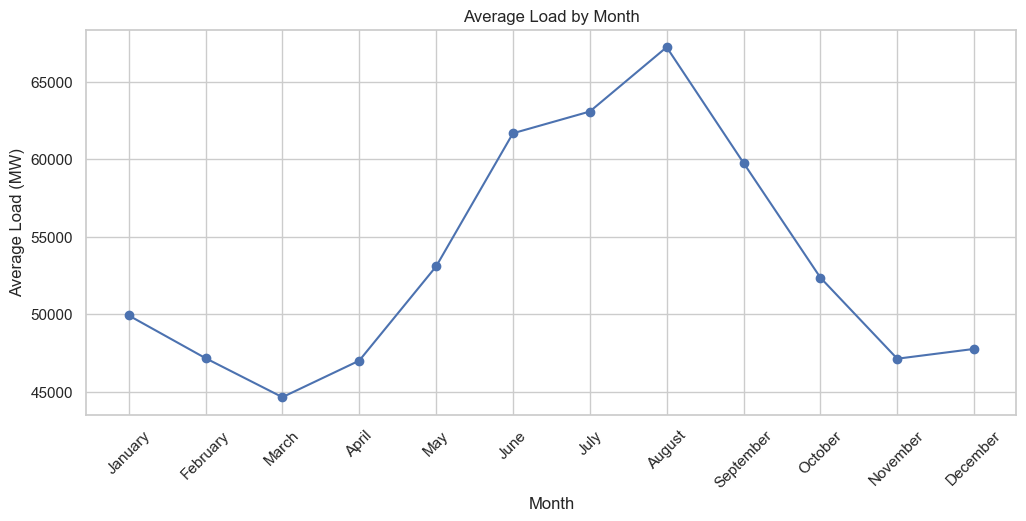

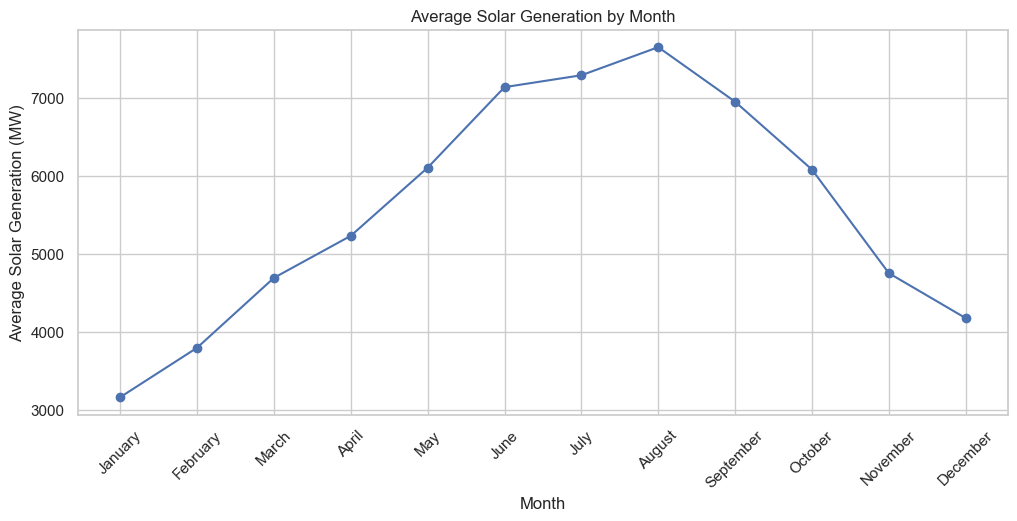

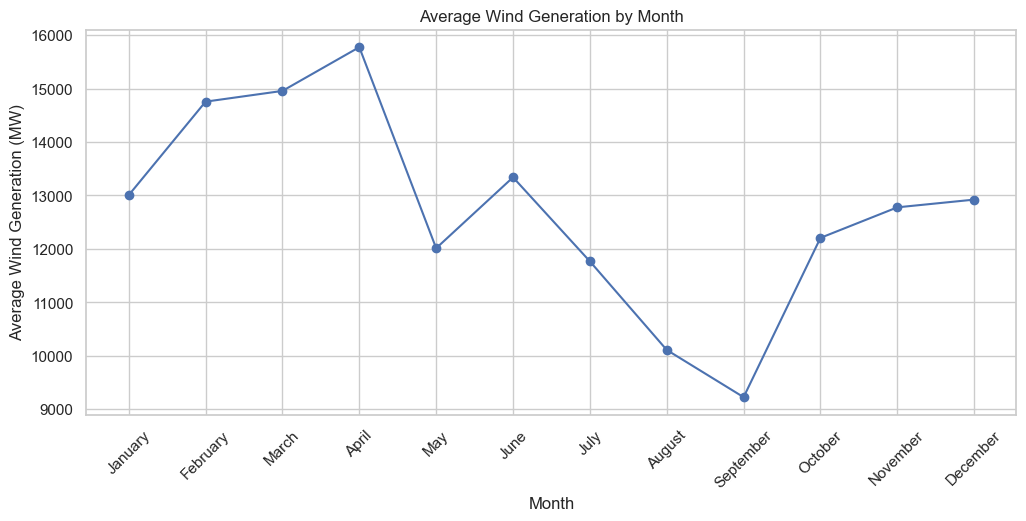

In [38]:
# Plot the average target value for each month.

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern["Load_MW"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Load (MW)")
plt.title("Average Load by Month")
plt.xticks(rotation=45)

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern["Solar_MW"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Solar Generation (MW)")
plt.title("Average Solar Generation by Month")
plt.xticks(rotation=45)

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern["Wind_MW"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Wind Generation (MW)")
plt.title("Average Wind Generation by Month")
plt.xticks(rotation=45)

plt.show()

In [39]:
# Calculate monthly averages separately for each year.

load_monthly_yearly = load_df.pivot_table(
    index="Month",
    columns="Year",
    values="Load_MW",
    aggfunc="mean"
)

solar_monthly_yearly = solar_df.pivot_table(
    index="Month",
    columns="Year",
    values="Solar_MW",
    aggfunc="mean"
)

wind_monthly_yearly = wind_df.pivot_table(
    index="Month",
    columns="Year",
    values="Wind_MW",
    aggfunc="mean"
)

print("Load")
display(load_monthly_yearly)

print("\nSolar")
display(solar_monthly_yearly)

print("\nWind")
display(wind_monthly_yearly)

Load


Year,2023,2024,2025
Month,,,
1,43363.258621,51451.845166,54938.985581
2,45167.453521,44189.219820,52239.024141
3,42965.890170,43587.386536,47382.594696
4,42873.938291,46719.368715,51415.170311
5,49230.148181,54006.026679,56002.397295
6,59593.778336,62030.943853,63400.517161
7,64023.895128,60191.236296,65024.928179
8,67814.322540,66572.128420,67309.949523
9,59983.756764,57304.706094,61999.681635



Solar


Year,2023,2024,2025
Month,,,
1,2041.202826,2999.136661,4456.848857
2,2145.924407,3802.039533,5448.980719
3,2765.294248,4395.666261,6922.459101
4,3549.463467,4823.084387,7325.651846
5,4058.164895,5498.291718,8759.372833
6,4842.907994,6915.960153,9650.532455
7,5252.381992,6899.228163,9714.824804
8,5220.336391,7771.524844,9953.223947
9,4508.288440,6702.079506,9638.958139



Wind


Year,2023,2024,2025
Month,,,
1,14677.907350,11479.969501,12861.165765
2,15148.854008,15729.501784,13353.552823
3,14921.239958,13736.862469,16211.646366
4,14191.484616,16144.027488,16990.053434
5,9988.652771,13585.415874,12462.132092
6,11363.982284,13920.402957,14735.015520
7,12036.931344,10918.820142,12344.060336
8,10606.961377,10164.759593,9553.936803
9,10011.686263,8273.278393,9388.464918


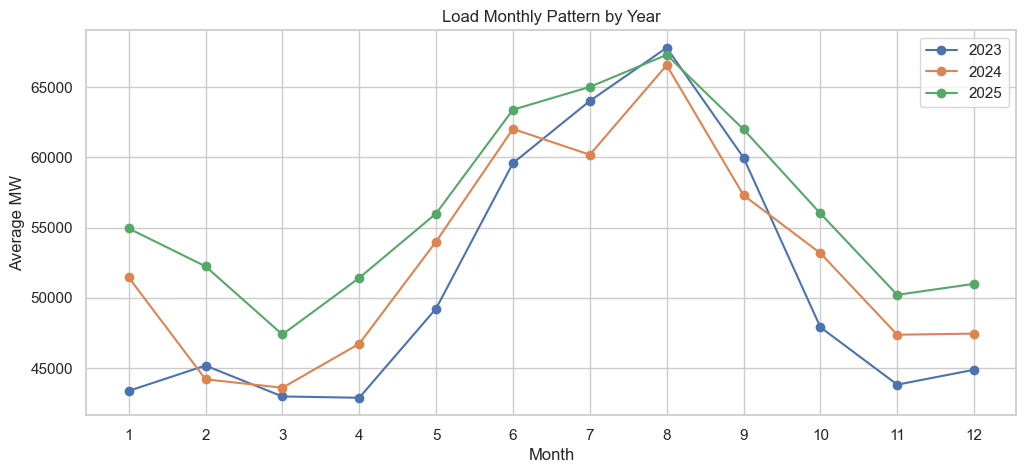

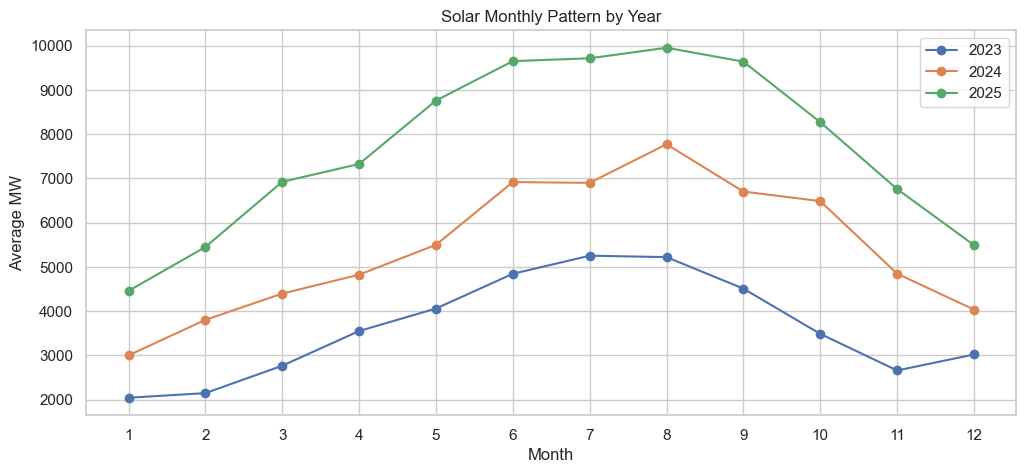

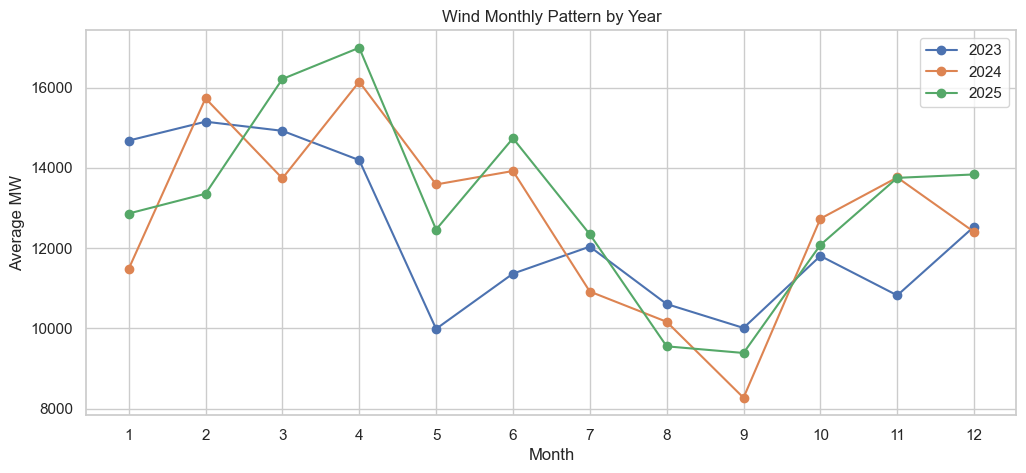

In [40]:
# Plot monthly patterns separately for each year.

figures = [
    ("Load", load_monthly_yearly),
    ("Solar", solar_monthly_yearly),
    ("Wind", wind_monthly_yearly)
]

for name, data in figures:

    plt.figure(figsize=(12, 5))

    for year in data.columns:
        plt.plot(
            data.index,
            data[year],
            marker="o",
            label=str(year)
        )

    plt.xlabel("Month")
    plt.ylabel("Average MW")
    plt.title(f"{name} Monthly Pattern by Year")
    plt.xticks(range(1, 13))
    plt.legend()

    plt.show()

In [41]:
# Calculate descriptive statistics for the three forecasting targets.

target_stats = pd.DataFrame({
    "Load_MW": load_df["Load_MW"].describe(),
    "Solar_MW": solar_df["Solar_MW"].describe(),
    "Wind_MW": wind_df["Wind_MW"].describe()
})

display(target_stats)

,Load_MW,Solar_MW,Wind_MW
count,26297.000000,26297.000000,26297.000000
mean,53442.643329,5594.988677,12722.005940
std,11035.943399,7433.929044,6697.712689
min,33681.540790,0.000010,37.929258
25%,45135.908281,0.407512,6984.308713
50%,50777.762847,336.094571,12330.326026
75%,59910.070037,10694.253827,18338.356289
max,85544.435964,29503.086634,28264.502331


In [42]:
# Calculate skewness and variation for each target.

additional_stats = pd.DataFrame({
    "Mean": [
        load_df["Load_MW"].mean(),
        solar_df["Solar_MW"].mean(),
        wind_df["Wind_MW"].mean()
    ],
    "Median": [
        load_df["Load_MW"].median(),
        solar_df["Solar_MW"].median(),
        wind_df["Wind_MW"].median()
    ],
    "Std": [
        load_df["Load_MW"].std(),
        solar_df["Solar_MW"].std(),
        wind_df["Wind_MW"].std()
    ],
    "Skewness": [
        load_df["Load_MW"].skew(),
        solar_df["Solar_MW"].skew(),
        wind_df["Wind_MW"].skew()
    ],
    "Min": [
        load_df["Load_MW"].min(),
        solar_df["Solar_MW"].min(),
        wind_df["Wind_MW"].min()
    ],
    "Max": [
        load_df["Load_MW"].max(),
        solar_df["Solar_MW"].max(),
        wind_df["Wind_MW"].max()
    ]
}, index=["Load", "Solar", "Wind"])

display(additional_stats)

,Mean,Median,Std,Skewness,Min,Max
Load,53442.643329,50777.762847,11035.943399,0.775698,33681.540790,85544.435964
Solar,5594.988677,336.094571,7433.929044,1.132663,0.000010,29503.086634
Wind,12722.005940,12330.326026,6697.712689,0.138580,37.929258,28264.502331


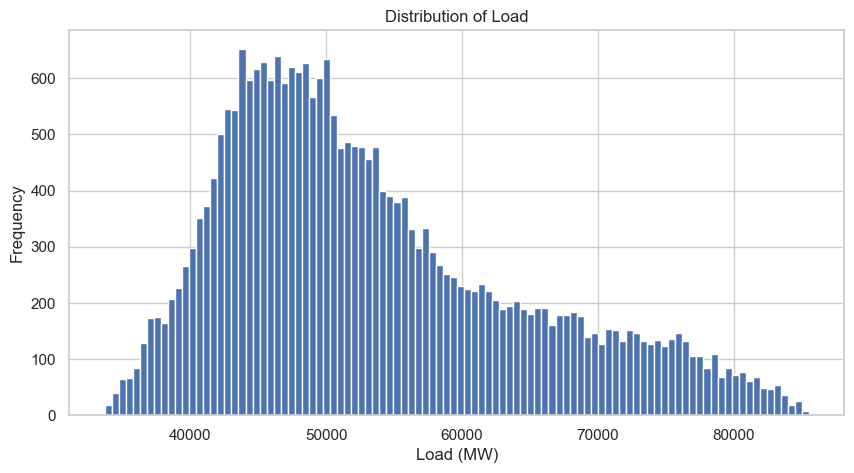

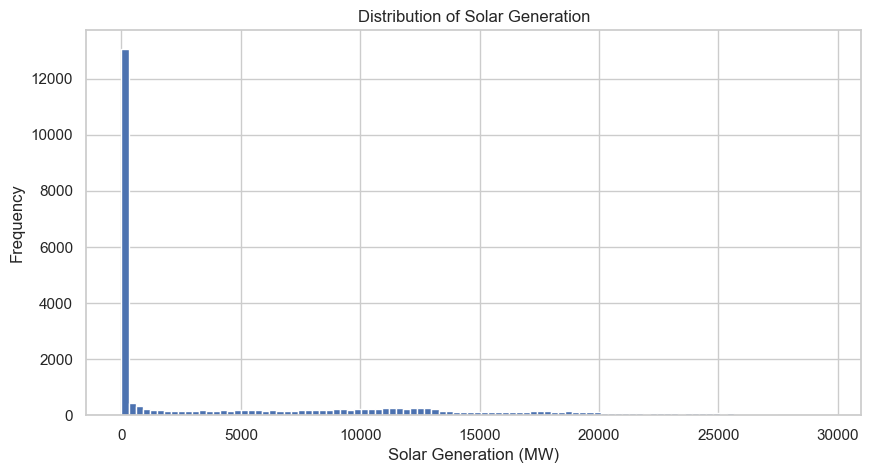

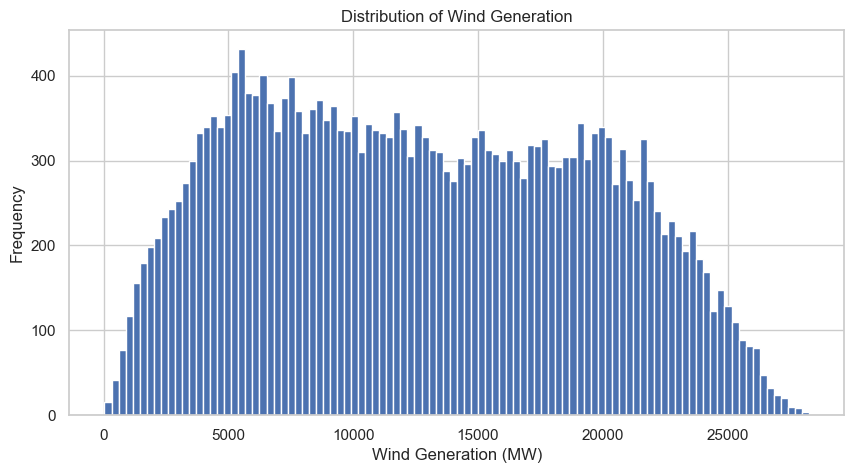

In [43]:
# Plot the distributions of load, solar, and wind generation.

plt.figure(figsize=(10, 5))

plt.hist(
    load_df["Load_MW"],
    bins=100
)

plt.xlabel("Load (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Load")

plt.show()


plt.figure(figsize=(10, 5))

plt.hist(
    solar_df["Solar_MW"],
    bins=100
)

plt.xlabel("Solar Generation (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Solar Generation")

plt.show()


plt.figure(figsize=(10, 5))

plt.hist(
    wind_df["Wind_MW"],
    bins=100
)

plt.xlabel("Wind Generation (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Wind Generation")

plt.show()

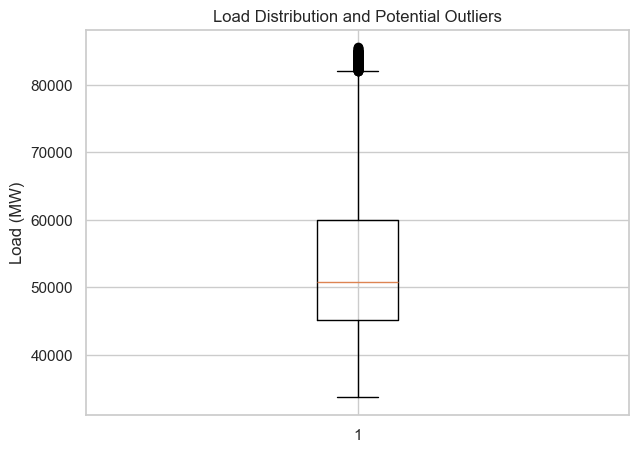

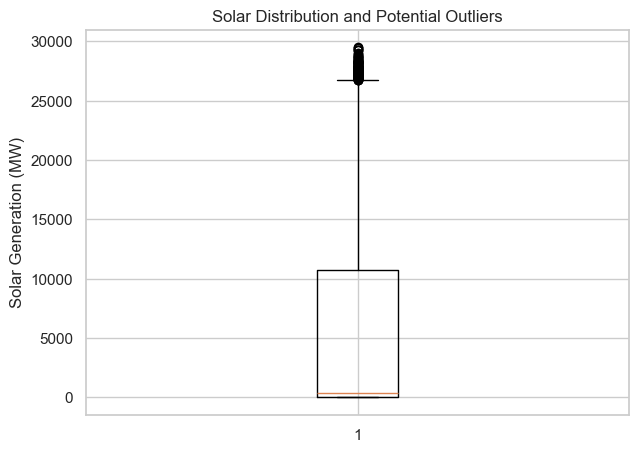

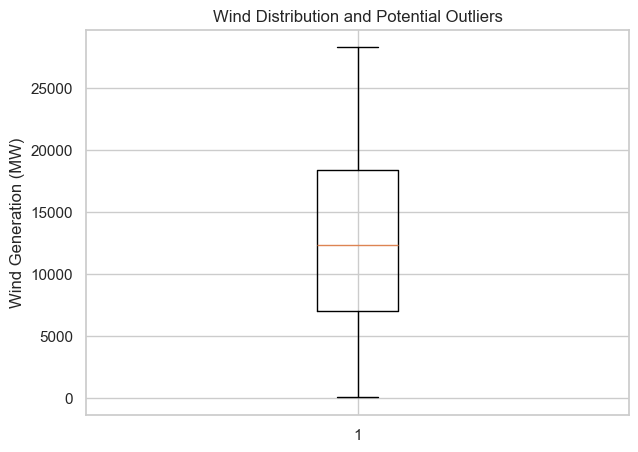

In [44]:
# Plot boxplots to identify potential extreme values.

plt.figure(figsize=(7, 5))

plt.boxplot(load_df["Load_MW"].dropna())

plt.ylabel("Load (MW)")
plt.title("Load Distribution and Potential Outliers")

plt.show()


plt.figure(figsize=(7, 5))

plt.boxplot(solar_df["Solar_MW"].dropna())

plt.ylabel("Solar Generation (MW)")
plt.title("Solar Distribution and Potential Outliers")

plt.show()


plt.figure(figsize=(7, 5))

plt.boxplot(wind_df["Wind_MW"].dropna())

plt.ylabel("Wind Generation (MW)")
plt.title("Wind Distribution and Potential Outliers")

plt.show()

# Correlation analysis

In [45]:
# Calculate correlations between load and its available features.

load_corr = load_df.select_dtypes(include=np.number).corr()["Load_MW"].sort_values(
    ascending=False
)

display(load_corr)

Load_MW      1.000000
T2M          0.621842
Hour         0.402945
Year         0.200987
DayOfYear    0.149664
Month        0.148030
IsHoliday   -0.019744
WS10M       -0.037333
DayOfWeek   -0.066573
IsWeekend   -0.079817
CLOUD_AMT   -0.138521
RH2M        -0.453082
Name: Load_MW, dtype: float64

In [46]:
# Calculate correlations between solar generation and its available features.

solar_corr = solar_df.select_dtypes(include=np.number).corr()["Solar_MW"].sort_values(
    ascending=False
)

display(solar_corr)

Solar_MW              1.000000
ALLSKY_SFC_SW_DWN     0.823454
ALLSKY_SFC_SW_DNI     0.764745
ALLSKY_SFC_SW_DIFF    0.636388
ALLSKY_KT             0.590335
T2M                   0.525200
Hour                  0.256178
Year                  0.223617
Month                 0.068610
DayOfYear             0.068313
WS10M                 0.046805
DayOfWeek            -0.004706
CLOUD_AMT            -0.171030
RH2M                 -0.649881
Name: Solar_MW, dtype: float64

In [47]:
# Calculate correlations between wind generation and its available features.

wind_corr = wind_df.select_dtypes(include=np.number).corr()["Wind_MW"].sort_values(
    ascending=False
)

display(wind_corr)

Wind_MW      1.000000
WS10M        0.570652
RH2M         0.197004
Year         0.048388
CLOUD_AMT    0.045300
DayOfWeek    0.027905
Hour        -0.114540
DayOfYear   -0.138208
Month       -0.138474
T2M         -0.149632
Name: Wind_MW, dtype: float64

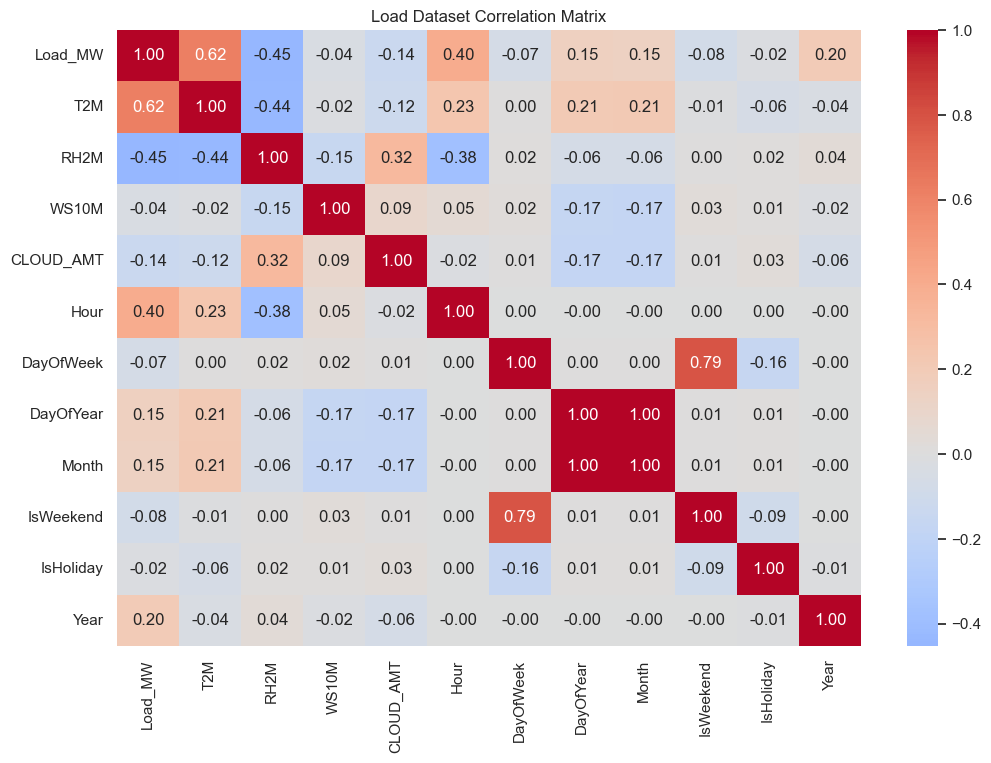

In [48]:
# Visualize correlations between load and its numerical features.

plt.figure(figsize=(12, 8))

sns.heatmap(
    load_df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Load Dataset Correlation Matrix")

plt.show()

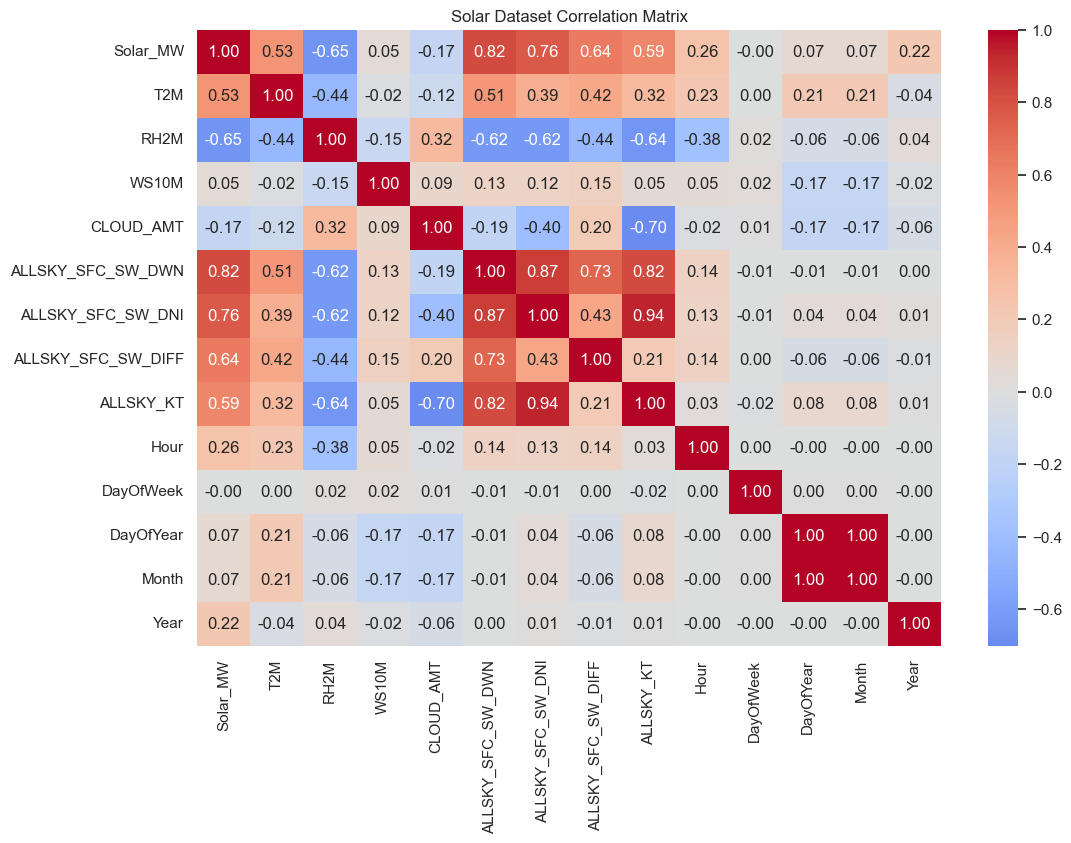

In [49]:
# Visualize correlations between solar generation and its numerical features.

plt.figure(figsize=(12, 8))

sns.heatmap(
    solar_df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Solar Dataset Correlation Matrix")

plt.show()

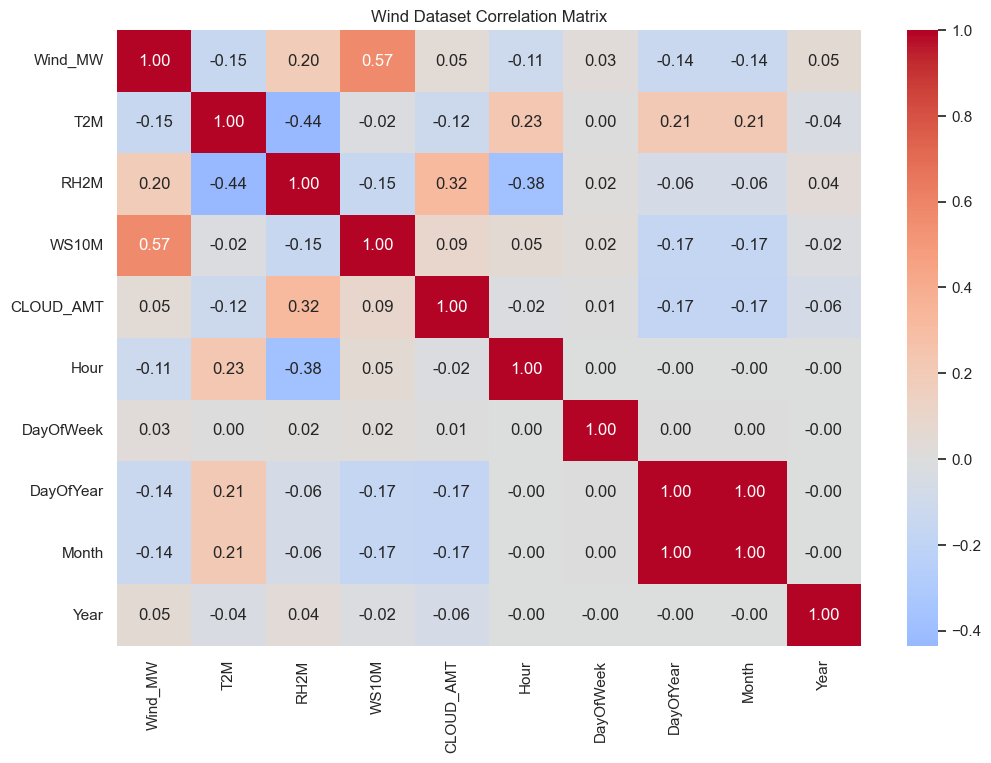

In [50]:
# Visualize correlations between wind generation and its numerical features.

plt.figure(figsize=(12, 8))

sns.heatmap(
    wind_df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Wind Dataset Correlation Matrix")

plt.show()

In [51]:
# Calculate correlations between each target and its previous time steps

def lag_correlations(df, target, max_lag):
    result = {}

    for lag in range(1, max_lag + 1):
        result[lag] = df[target].corr(df[target].shift(lag))

    return pd.Series(result, name=target)


load_lag_corr = lag_correlations(load_df, "Load_MW", 168)
solar_lag_corr = lag_correlations(solar_df, "Solar_MW", 48)
wind_lag_corr = lag_correlations(wind_df, "Wind_MW", 48)

print("Load lag correlations:")
display(load_lag_corr)

print("\nSolar lag correlations:")
display(solar_lag_corr)

print("\nWind lag correlations:")
display(wind_lag_corr)

Load lag correlations:


1      0.985073
2      0.943846
3      0.881620
4      0.803494
5      0.715247
         ...   
164    0.664644
165    0.736853
166    0.793715
167    0.830730
168    0.843508
Name: Load_MW, Length: 168, dtype: float64


Solar lag correlations:


1     0.938030
2     0.794396
3     0.621040
4     0.436987
5     0.249318
6     0.062992
7    -0.115790
8    -0.276502
9    -0.405004
10   -0.492661
11   -0.541351
12   -0.556428
13   -0.541119
14   -0.492463
15   -0.405590
16   -0.279225
17   -0.122191
18    0.051994
19    0.233164
20    0.414982
21    0.592080
22    0.756970
23    0.890920
24    0.946188
25    0.886873
26    0.750594
27    0.584622
28    0.407056
29    0.225068
30    0.043992
31   -0.129632
32   -0.285487
33   -0.410093
34   -0.495095
35   -0.542296
36   -0.556938
37   -0.542017
38   -0.494572
39   -0.409821
40   -0.286445
41   -0.132831
42    0.038255
43    0.216887
44    0.396426
45    0.571053
46    0.733001
47    0.864027
48    0.918685
Name: Solar_MW, dtype: float64


Wind lag correlations:


1     0.982208
2     0.939642
3     0.883215
4     0.818305
5     0.749041
6     0.678971
7     0.611208
8     0.548206
9     0.491817
10    0.443990
11    0.406347
12    0.379609
13    0.363483
14    0.357597
15    0.360352
16    0.369471
17    0.382649
18    0.397822
19    0.413071
20    0.426595
21    0.436585
22    0.441346
23    0.439314
24    0.427181
25    0.402299
26    0.368825
27    0.330739
28    0.289771
29    0.247484
30    0.205517
31    0.165478
32    0.128810
33    0.096878
34    0.071329
35    0.053792
36    0.045108
37    0.045124
38    0.053539
39    0.068917
40    0.089427
41    0.113277
42    0.138952
43    0.164922
44    0.189617
45    0.211255
46    0.228158
47    0.238946
48    0.240741
Name: Wind_MW, dtype: float64

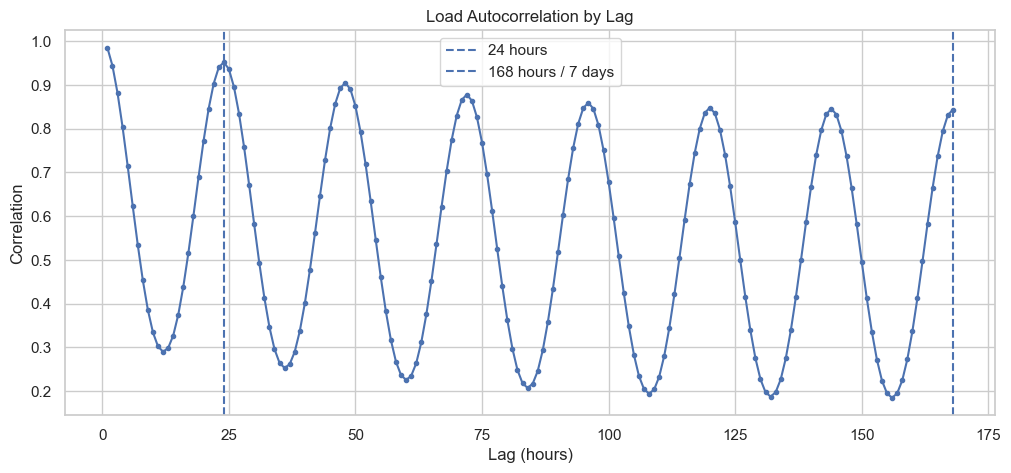

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    load_lag_corr.index,
    load_lag_corr.values,
    marker="o",
    markersize=3
)

plt.axvline(24, linestyle="--", label="24 hours")
plt.axvline(168, linestyle="--", label="168 hours / 7 days")

plt.title("Load Autocorrelation by Lag")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

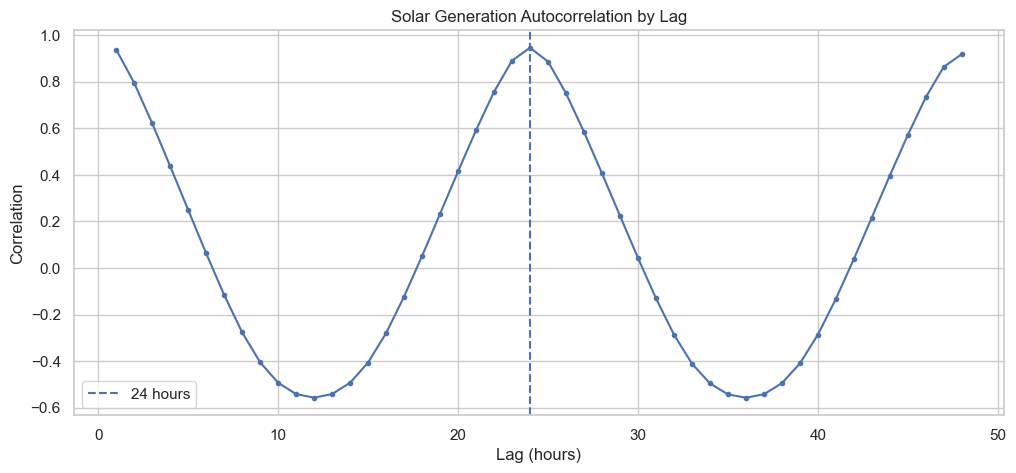

In [53]:
plt.figure(figsize=(12, 5))

plt.plot(
    solar_lag_corr.index,
    solar_lag_corr.values,
    marker="o",
    markersize=3
)

plt.axvline(24, linestyle="--", label="24 hours")

plt.title("Solar Generation Autocorrelation by Lag")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

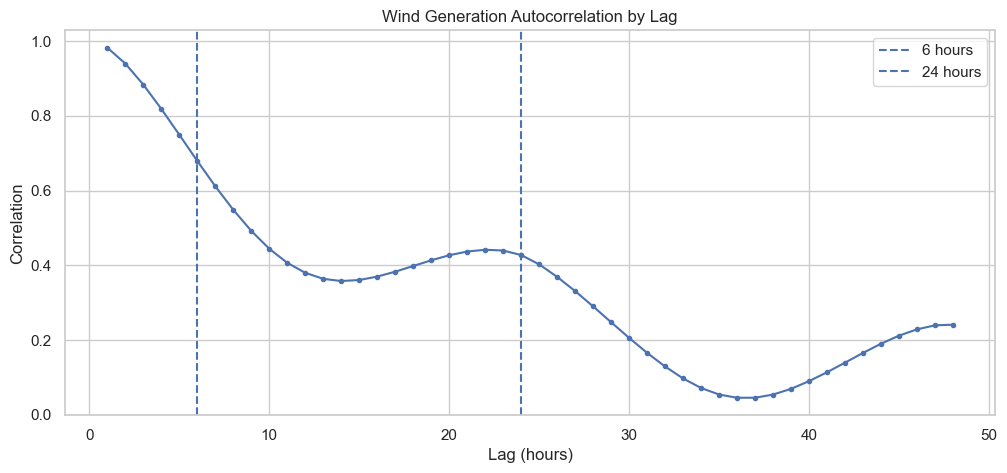

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(
    wind_lag_corr.index,
    wind_lag_corr.values,
    marker="o",
    markersize=3
)

plt.axvline(6, linestyle="--", label="6 hours")
plt.axvline(24, linestyle="--", label="24 hours")

plt.title("Wind Generation Autocorrelation by Lag")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

In [55]:
# Create cyclic time features for all three datasets

for df in [load_df, solar_df, wind_df]:

    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

    df["DayOfWeek_sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7)
    df["DayOfWeek_cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7)

    df["DayOfYear_sin"] = np.sin(2 * np.pi * df["DayOfYear"] / 365.25)
    df["DayOfYear_cos"] = np.cos(2 * np.pi * df["DayOfYear"] / 365.25)

In [56]:
print("Load:")
display(load_df[
    [
        "Hour",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "DayOfYear",
        "DayOfYear_sin",
        "DayOfYear_cos"
    ]
].head())

print("Solar:")
display(solar_df[
    [
        "Hour",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "DayOfYear",
        "DayOfYear_sin",
        "DayOfYear_cos"
    ]
].head())

print("Wind:")
display(wind_df[
    [
        "Hour",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "DayOfYear",
        "DayOfYear_sin",
        "DayOfYear_cos"
    ]
].head())

Load:


,Hour,Hour_sin,Hour_cos,DayOfWeek,DayOfWeek_sin,DayOfWeek_cos,DayOfYear,DayOfYear_sin,DayOfYear_cos
0,1,0.258819,0.965926,6,-0.781831,0.62349,1,0.017202,0.999852
1,2,0.500000,0.866025,6,-0.781831,0.62349,1,0.017202,0.999852
2,3,0.707107,0.707107,6,-0.781831,0.62349,1,0.017202,0.999852
3,4,0.866025,0.500000,6,-0.781831,0.62349,1,0.017202,0.999852
4,5,0.965926,0.258819,6,-0.781831,0.62349,1,0.017202,0.999852


Solar:


,Hour,Hour_sin,Hour_cos,DayOfWeek,DayOfWeek_sin,DayOfWeek_cos,DayOfYear,DayOfYear_sin,DayOfYear_cos
0,1,0.258819,0.965926,6,-0.781831,0.62349,1,0.017202,0.999852
1,2,0.500000,0.866025,6,-0.781831,0.62349,1,0.017202,0.999852
2,3,0.707107,0.707107,6,-0.781831,0.62349,1,0.017202,0.999852
3,4,0.866025,0.500000,6,-0.781831,0.62349,1,0.017202,0.999852
4,5,0.965926,0.258819,6,-0.781831,0.62349,1,0.017202,0.999852


Wind:


,Hour,Hour_sin,Hour_cos,DayOfWeek,DayOfWeek_sin,DayOfWeek_cos,DayOfYear,DayOfYear_sin,DayOfYear_cos
0,1,0.258819,0.965926,6,-0.781831,0.62349,1,0.017202,0.999852
1,2,0.500000,0.866025,6,-0.781831,0.62349,1,0.017202,0.999852
2,3,0.707107,0.707107,6,-0.781831,0.62349,1,0.017202,0.999852
3,4,0.866025,0.500000,6,-0.781831,0.62349,1,0.017202,0.999852
4,5,0.965926,0.258819,6,-0.781831,0.62349,1,0.017202,0.999852


In [57]:
# ============================================================
# VERIFY CYCLIC FEATURES
# ============================================================

cyclic_cols = [
    "Hour_sin", "Hour_cos",
    "DayOfWeek_sin", "DayOfWeek_cos",
    "DayOfYear_sin", "DayOfYear_cos"
]

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    
    print(f"\n{name}")
    print("-" * 50)
    
    print("Missing values:")
    print(df[cyclic_cols].isna().sum())
    
    print("\nRange:")
    print(df[cyclic_cols].agg(["min", "max"]).T)


Load
--------------------------------------------------
Missing values:
Hour_sin         0
Hour_cos         0
DayOfWeek_sin    0
DayOfWeek_cos    0
DayOfYear_sin    0
DayOfYear_cos    0
dtype: int64

Range:
                    min       max
Hour_sin      -1.000000  1.000000
Hour_cos      -1.000000  1.000000
DayOfWeek_sin -0.974928  0.974928
DayOfWeek_cos -0.900969  1.000000
DayOfYear_sin -0.999999  0.999986
DayOfYear_cos -0.999979  0.999991

Solar
--------------------------------------------------
Missing values:
Hour_sin         0
Hour_cos         0
DayOfWeek_sin    0
DayOfWeek_cos    0
DayOfYear_sin    0
DayOfYear_cos    0
dtype: int64

Range:
                    min       max
Hour_sin      -1.000000  1.000000
Hour_cos      -1.000000  1.000000
DayOfWeek_sin -0.974928  0.974928
DayOfWeek_cos -0.900969  1.000000
DayOfYear_sin -0.999999  0.999986
DayOfYear_cos -0.999979  0.999991

Wind
--------------------------------------------------
Missing values:
Hour_sin         0
Hour_cos       

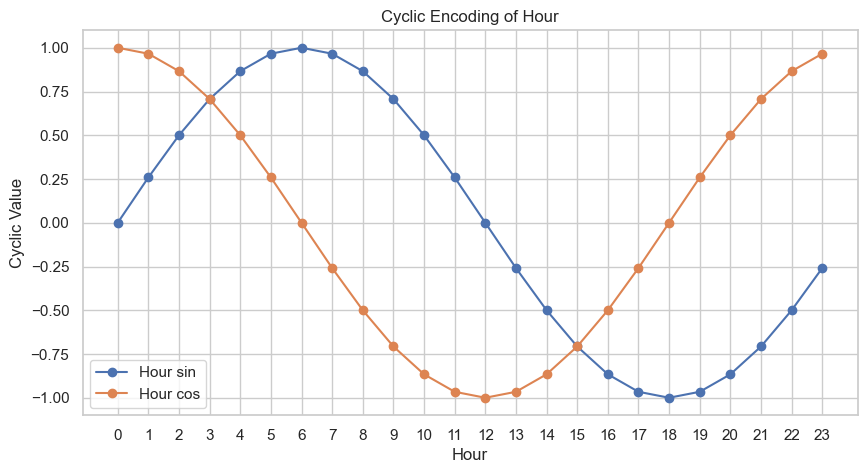

In [58]:
import matplotlib.pyplot as plt
import numpy as np

hours = np.arange(24)

hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

plt.figure(figsize=(10, 5))

plt.plot(hours, hour_sin, marker="o", label="Hour sin")
plt.plot(hours, hour_cos, marker="o", label="Hour cos")

plt.xlabel("Hour")
plt.ylabel("Cyclic Value")
plt.title("Cyclic Encoding of Hour")
plt.xticks(range(24))
plt.grid(True)
plt.legend()

plt.show()

# Feature selection

In [59]:
# ============================================================
# FEATURE SELECTION — STEP 1
# Define candidate features
# ============================================================

load_candidates = [
    "T2M",
    "RH2M",
    "WS10M",
    "CLOUD_AMT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos",

    # Calendar indicators
    "IsWeekend",
    "IsHoliday"
]


solar_candidates = [
    "T2M",
    "RH2M",
    "WS10M",
    "CLOUD_AMT",

    # Solar radiation features
    "ALLSKY_SFC_SW_DWN",
    "ALLSKY_SFC_SW_DNI",
    "ALLSKY_SFC_SW_DIFF",
    "ALLSKY_KT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


wind_candidates = [
    "T2M",
    "RH2M",
    "WS10M",
    "CLOUD_AMT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


print("LOAD CANDIDATES")
print(load_candidates)

print("\nSOLAR CANDIDATES")
print(solar_candidates)

print("\nWIND CANDIDATES")
print(wind_candidates)

LOAD CANDIDATES
['T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'IsWeekend', 'IsHoliday']

SOLAR CANDIDATES
['T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'ALLSKY_KT', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']

WIND CANDIDATES
['T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [60]:
# ============================================================
# FEATURE SELECTION — STEP 2
# Check candidate columns
# ============================================================

for name, df, candidates in [
    ("LOAD", load_df, load_candidates),
    ("SOLAR", solar_df, solar_candidates),
    ("WIND", wind_df, wind_candidates)
]:
    
    missing = [col for col in candidates if col not in df.columns]
    
    print(f"\n{name}")
    print("-" * 60)
    
    if len(missing) == 0:
        print("All candidate features are available.")
    else:
        print("Missing features:")
        print(missing)


LOAD
------------------------------------------------------------
All candidate features are available.

SOLAR
------------------------------------------------------------
All candidate features are available.

WIND
------------------------------------------------------------
All candidate features are available.


In [61]:
# ============================================================
# FEATURE SELECTION — STEP 3
# Target correlations
# ============================================================

load_corr = (
    load_df[["Load_MW"] + load_candidates]
    .corr()["Load_MW"]
    .drop("Load_MW")
    .sort_values(key=abs, ascending=False)
)

solar_corr = (
    solar_df[["Solar_MW"] + solar_candidates]
    .corr()["Solar_MW"]
    .drop("Solar_MW")
    .sort_values(key=abs, ascending=False)
)

wind_corr = (
    wind_df[["Wind_MW"] + wind_candidates]
    .corr()["Wind_MW"]
    .drop("Wind_MW")
    .sort_values(key=abs, ascending=False)
)


print("LOAD — CORRELATION WITH TARGET")
print("=" * 60)
display(load_corr)

print("\nSOLAR — CORRELATION WITH TARGET")
print("=" * 60)
display(solar_corr)

print("\nWIND — CORRELATION WITH TARGET")
print("=" * 60)
display(wind_corr)

LOAD — CORRELATION WITH TARGET


T2M              0.621842
DayOfYear_cos   -0.511291
Hour_sin        -0.467154
RH2M            -0.453082
DayOfYear_sin   -0.318622
Hour_cos        -0.145227
CLOUD_AMT       -0.138521
IsWeekend       -0.079817
DayOfWeek_sin    0.063250
WS10M           -0.037333
IsHoliday       -0.019744
DayOfWeek_cos   -0.016143
Name: Load_MW, dtype: float64


SOLAR — CORRELATION WITH TARGET


ALLSKY_SFC_SW_DWN     0.823454
ALLSKY_SFC_SW_DNI     0.764745
Hour_cos             -0.696547
RH2M                 -0.649881
ALLSKY_SFC_SW_DIFF    0.636388
ALLSKY_KT             0.590335
T2M                   0.525200
Hour_sin             -0.362052
DayOfYear_cos        -0.174812
CLOUD_AMT            -0.171030
DayOfYear_sin        -0.080016
WS10M                 0.046805
DayOfWeek_sin         0.003192
DayOfWeek_cos         0.002482
Name: Solar_MW, dtype: float64


WIND — CORRELATION WITH TARGET


WS10M            0.570652
Hour_cos         0.300083
DayOfYear_sin    0.206317
RH2M             0.197004
T2M             -0.149632
Hour_sin         0.111427
DayOfYear_cos    0.092887
CLOUD_AMT        0.045300
DayOfWeek_sin   -0.028686
DayOfWeek_cos   -0.007819
Name: Wind_MW, dtype: float64

In [62]:
# ============================================================
# FEATURE SELECTION — STEP 4
# Feature-to-feature correlations
# ============================================================

print("LOAD FEATURE CORRELATION")
display(
    load_df[load_candidates]
    .corr()
    .round(2)
)

print("\nSOLAR FEATURE CORRELATION")
display(
    solar_df[solar_candidates]
    .corr()
    .round(2)
)

print("\nWIND FEATURE CORRELATION")
display(
    wind_df[wind_candidates]
    .corr()
    .round(2)
)

LOAD FEATURE CORRELATION


,T2M,RH2M,WS10M,CLOUD_AMT,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,DayOfYear_sin,DayOfYear_cos,IsWeekend,IsHoliday
T2M,1.00,-0.44,-0.02,-0.12,-0.31,-0.31,0.00,-0.02,-0.25,-0.72,-0.01,-0.06
RH2M,-0.44,1.00,-0.15,0.32,0.50,0.45,-0.00,-0.03,0.14,0.05,0.00,0.02
WS10M,-0.02,-0.15,1.00,0.09,-0.06,-0.14,-0.03,0.02,0.21,0.11,0.03,0.01
CLOUD_AMT,-0.12,0.32,0.09,1.00,0.03,0.01,0.01,-0.01,0.26,0.06,0.01,0.03
Hour_sin,-0.31,0.50,-0.06,0.03,1.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00
Hour_cos,-0.31,0.45,-0.14,0.01,0.00,1.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00
DayOfWeek_sin,0.00,-0.00,-0.03,0.01,0.00,-0.00,1.00,-0.00,0.00,0.00,-0.79,0.03
DayOfWeek_cos,-0.02,-0.03,0.02,-0.01,-0.00,0.00,-0.00,1.00,-0.00,0.00,0.18,0.10
DayOfYear_sin,-0.25,0.14,0.21,0.26,-0.00,-0.00,0.00,-0.00,1.00,-0.00,-0.00,-0.04
DayOfYear_cos,-0.72,0.05,0.11,0.06,0.00,-0.00,0.00,0.00,-0.00,1.00,-0.00,0.06



SOLAR FEATURE CORRELATION


,T2M,RH2M,WS10M,CLOUD_AMT,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,DayOfYear_sin,DayOfYear_cos
T2M,1.00,-0.44,-0.02,-0.12,0.51,0.39,0.42,0.32,-0.31,-0.31,0.00,-0.02,-0.25,-0.72
RH2M,-0.44,1.00,-0.15,0.32,-0.62,-0.62,-0.44,-0.64,0.50,0.45,-0.00,-0.03,0.14,0.05
WS10M,-0.02,-0.15,1.00,0.09,0.13,0.12,0.15,0.05,-0.06,-0.14,-0.03,0.02,0.21,0.11
CLOUD_AMT,-0.12,0.32,0.09,1.00,-0.19,-0.40,0.20,-0.70,0.03,0.01,0.01,-0.01,0.26,0.06
ALLSKY_SFC_SW_DWN,0.51,-0.62,0.13,-0.19,1.00,0.87,0.73,0.82,-0.18,-0.79,0.00,0.00,-0.00,-0.19
ALLSKY_SFC_SW_DNI,0.39,-0.62,0.12,-0.40,0.87,1.00,0.43,0.94,-0.15,-0.71,0.00,0.01,-0.06,-0.05
ALLSKY_SFC_SW_DIFF,0.42,-0.44,0.15,0.20,0.73,0.43,1.00,0.21,-0.16,-0.73,-0.00,-0.00,0.08,-0.20
ALLSKY_KT,0.32,-0.64,0.05,-0.70,0.82,0.94,0.21,1.00,-0.09,-0.47,-0.00,0.02,-0.13,-0.04
Hour_sin,-0.31,0.50,-0.06,0.03,-0.18,-0.15,-0.16,-0.09,1.00,0.00,0.00,-0.00,-0.00,0.00
Hour_cos,-0.31,0.45,-0.14,0.01,-0.79,-0.71,-0.73,-0.47,0.00,1.00,-0.00,0.00,-0.00,-0.00



WIND FEATURE CORRELATION


,T2M,RH2M,WS10M,CLOUD_AMT,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,DayOfYear_sin,DayOfYear_cos
T2M,1.00,-0.44,-0.02,-0.12,-0.31,-0.31,0.00,-0.02,-0.25,-0.72
RH2M,-0.44,1.00,-0.15,0.32,0.50,0.45,-0.00,-0.03,0.14,0.05
WS10M,-0.02,-0.15,1.00,0.09,-0.06,-0.14,-0.03,0.02,0.21,0.11
CLOUD_AMT,-0.12,0.32,0.09,1.00,0.03,0.01,0.01,-0.01,0.26,0.06
Hour_sin,-0.31,0.50,-0.06,0.03,1.00,0.00,0.00,-0.00,-0.00,0.00
Hour_cos,-0.31,0.45,-0.14,0.01,0.00,1.00,-0.00,0.00,-0.00,-0.00
DayOfWeek_sin,0.00,-0.00,-0.03,0.01,0.00,-0.00,1.00,-0.00,0.00,0.00
DayOfWeek_cos,-0.02,-0.03,0.02,-0.01,-0.00,0.00,-0.00,1.00,-0.00,0.00
DayOfYear_sin,-0.25,0.14,0.21,0.26,-0.00,-0.00,0.00,-0.00,1.00,-0.00
DayOfYear_cos,-0.72,0.05,0.11,0.06,0.00,-0.00,0.00,0.00,-0.00,1.00


In [63]:
# ============================================================
# FEATURE SELECTION — STEP 5
# Find highly correlated feature pairs
# ============================================================

def highly_correlated_pairs(df, features, threshold=0.80):
    
    corr_matrix = df[features].corr().abs()
    
    pairs = []
    
    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            
            corr_value = corr_matrix.iloc[i, j]
            
            if corr_value >= threshold:
                pairs.append(
                    (
                        features[i],
                        features[j],
                        corr_value
                    )
                )
    
    return sorted(
        pairs,
        key=lambda x: x[2],
        reverse=True
    )


print("LOAD — HIGH CORRELATION PAIRS")
for pair in highly_correlated_pairs(load_df, load_candidates):
    print(pair)


print("\nSOLAR — HIGH CORRELATION PAIRS")
for pair in highly_correlated_pairs(solar_df, solar_candidates):
    print(pair)


print("\nWIND — HIGH CORRELATION PAIRS")
for pair in highly_correlated_pairs(wind_df, wind_candidates):
    print(pair)

LOAD — HIGH CORRELATION PAIRS

SOLAR — HIGH CORRELATION PAIRS
('ALLSKY_SFC_SW_DNI', 'ALLSKY_KT', np.float64(0.9383538630125388))
('ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', np.float64(0.8734349113448012))
('ALLSKY_SFC_SW_DWN', 'ALLSKY_KT', np.float64(0.8216159847236312))

WIND — HIGH CORRELATION PAIRS


In [64]:
# ============================================================
# FEATURE SELECTION — STEP 6
# Missing-value percentage
# ============================================================

def missing_percentage(df, features):
    
    return (
        df[features]
        .isna()
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )


print("LOAD")
display(missing_percentage(load_df, load_candidates))

print("\nSOLAR")
display(missing_percentage(solar_df, solar_candidates))

print("\nWIND")
display(missing_percentage(wind_df, wind_candidates))

LOAD


T2M              0.0
RH2M             0.0
WS10M            0.0
CLOUD_AMT        0.0
Hour_sin         0.0
Hour_cos         0.0
DayOfWeek_sin    0.0
DayOfWeek_cos    0.0
DayOfYear_sin    0.0
DayOfYear_cos    0.0
IsWeekend        0.0
IsHoliday        0.0
dtype: float64


SOLAR


ALLSKY_KT             47.552953
T2M                    0.000000
WS10M                  0.000000
CLOUD_AMT              0.000000
ALLSKY_SFC_SW_DWN      0.000000
RH2M                   0.000000
ALLSKY_SFC_SW_DNI      0.000000
ALLSKY_SFC_SW_DIFF     0.000000
Hour_sin               0.000000
Hour_cos               0.000000
DayOfWeek_sin          0.000000
DayOfWeek_cos          0.000000
DayOfYear_sin          0.000000
DayOfYear_cos          0.000000
dtype: float64


WIND


T2M              0.0
RH2M             0.0
WS10M            0.0
CLOUD_AMT        0.0
Hour_sin         0.0
Hour_cos         0.0
DayOfWeek_sin    0.0
DayOfWeek_cos    0.0
DayOfYear_sin    0.0
DayOfYear_cos    0.0
dtype: float64

In [65]:
# ============================================================
# STEP 1 — DEFINE TARGETS AND FEATURES
# ============================================================

# -------------------------
# LOAD
# -------------------------

load_target = "Load_MW"

load_features = [
    # Past load
    "Load_MW_lag1",
    "Load_MW_lag24",
    "Load_MW_lag168",

    # Weather
    "T2M",
    "RH2M",
    "CLOUD_AMT",
    "WS10M",

    # Calendar
    "IsWeekend",
    "IsHoliday",

    # Cyclic features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# -------------------------
# SOLAR
# -------------------------

solar_target = "Solar_MW"

solar_features = [
    # Past solar generation
    "Solar_MW_lag1",
    "Solar_MW_lag24",

    # Weather
    "CLOUD_AMT",
    "WS10M",
    "RH2M",

    # Solar radiation / insolation
    "ALLSKY_SFC_SW_DWN",

    # Cyclic features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# -------------------------
# WIND
# -------------------------

wind_target = "Wind_MW"

wind_features = [
    # Past wind generation
    "Wind_MW_lag1",
    "Wind_MW_lag6",
    "Wind_MW_lag24",

    # Weather
    "WS10M",
    "T2M",

    # Wind direction
    "WindDirection",

    # Cyclic features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


print("LOAD FEATURES:")
print(load_features)

print("\nSOLAR FEATURES:")
print(solar_features)

print("\nWIND FEATURES:")
print(wind_features)

LOAD FEATURES:
['Load_MW_lag1', 'Load_MW_lag24', 'Load_MW_lag168', 'T2M', 'RH2M', 'CLOUD_AMT', 'WS10M', 'IsWeekend', 'IsHoliday', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']

SOLAR FEATURES:
['Solar_MW_lag1', 'Solar_MW_lag24', 'CLOUD_AMT', 'WS10M', 'RH2M', 'ALLSKY_SFC_SW_DWN', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']

WIND FEATURES:
['Wind_MW_lag1', 'Wind_MW_lag6', 'Wind_MW_lag24', 'WS10M', 'T2M', 'WindDirection', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [66]:
print(wind_df.columns.tolist())

['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'Datetime_Local', 'Year', 'DayName', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


# test/train split

In [67]:
# ===========================================================
# STEP 1 — 2-YEAR TRAINING / 1-YEAR TESTING SPLIT
# ============================================================

train_end = pd.Timestamp("2024-12-31 23:00:00+00:00")
test_start = pd.Timestamp("2025-01-01 00:00:00+00:00")


def split_train_test(df):
    
    train = df[df["Datetime_UTC"] <= train_end].copy()
    test = df[df["Datetime_UTC"] >= test_start].copy()
    
    return train, test


load_train, load_test = split_train_test(load_df)

solar_train, solar_test = split_train_test(solar_df)

wind_train, wind_test = split_train_test(wind_df)

In [68]:
# ============================================================
# STEP 3 — VERIFY TRAIN / TEST SPLIT
# ============================================================

datasets = {
    "LOAD": (load_train, load_test),
    "SOLAR": (solar_train, solar_test),
    "WIND": (wind_train, wind_test)
}

for name, (train, test) in datasets.items():
    
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    
    print("\nTRAINING DATA")
    print("Start :", train["Datetime_UTC"].min())
    print("End   :", train["Datetime_UTC"].max())
    print("Rows  :", len(train))
    
    print("\nTESTING DATA")
    print("Start :", test["Datetime_UTC"].min())
    print("End   :", test["Datetime_UTC"].max())
    print("Rows  :", len(test))


LOAD

TRAINING DATA
Start : 2023-01-01 07:00:00+00:00
End   : 2024-12-31 23:00:00+00:00
Rows  : 17537

TESTING DATA
Start : 2025-01-01 00:00:00+00:00
End   : 2025-12-31 23:00:00+00:00
Rows  : 8760

SOLAR

TRAINING DATA
Start : 2023-01-01 07:00:00+00:00
End   : 2024-12-31 23:00:00+00:00
Rows  : 17537

TESTING DATA
Start : 2025-01-01 00:00:00+00:00
End   : 2025-12-31 23:00:00+00:00
Rows  : 8760

WIND

TRAINING DATA
Start : 2023-01-01 07:00:00+00:00
End   : 2024-12-31 23:00:00+00:00
Rows  : 17537

TESTING DATA
Start : 2025-01-01 00:00:00+00:00
End   : 2025-12-31 23:00:00+00:00
Rows  : 8760


In [69]:
# ============================================================
# STEP 4 — CHECK FOR TRAIN / TEST OVERLAP
# ============================================================

for name, train, test in [
    ("LOAD", load_train, load_test),
    ("SOLAR", solar_train, solar_test),
    ("WIND", wind_train, wind_test)
]:
    
    overlap = set(train["Datetime_UTC"]).intersection(
        set(test["Datetime_UTC"])
    )
    
    print(f"{name}: {len(overlap)} overlapping timestamps")

LOAD: 0 overlapping timestamps
SOLAR: 0 overlapping timestamps
WIND: 0 overlapping timestamps


In [70]:
# ============================================================
# STEP 5 — FINAL FEATURE DEFINITIONS
# ============================================================

load_features = [
    "Load_MW",
    "RH2M",
    "IsWeekend",
    "IsHoliday",
    "T2M",
    "CLOUD_AMT",
    "WS10M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


solar_features = [
    "Solar_MW",
    "ALLSKY_SFC_SW_DWN",
    "CLOUD_AMT",
    "WS10M",
    "RH2M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


wind_features = [
    "Wind_MW",
    "WS10M",
    "WindDirection",
    "T2M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


print("Load features :", len(load_features))
print("Solar features:", len(solar_features))
print("Wind features :", len(wind_features))

Load features : 13
Solar features: 11
Wind features : 10


In [71]:
print("WIND TRAIN COLUMNS:")
print(wind_train.columns.tolist())

WIND TRAIN COLUMNS:
['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'Datetime_Local', 'Year', 'DayName', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [72]:
# ============================================================
# STEP 6.1 — VERIFY FINAL FEATURES
# ============================================================

# ------------------------------------------------------------
# LOAD FEATURES
# ------------------------------------------------------------

load_features = [
    "Load_MW",          # past load through LSTM sequence
    "RH2M",             # Humidity
    "IsWeekend",
    "IsHoliday",
    "T2M",              # Temperature
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos",
    "CLOUD_AMT",        # Cloud cover
    "WS10M"             # Wind speed
]


# ------------------------------------------------------------
# SOLAR FEATURES
# ------------------------------------------------------------

solar_features = [
    "Solar_MW",         # past generation through LSTM sequence
    "ALLSKY_SFC_SW_DWN", # Insolation / solar radiation
    "CLOUD_AMT",        # Cloud cover
    "WS10M",             # Wind speed
    "RH2M",              # Humidity
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# ------------------------------------------------------------
# WIND FEATURES
# ------------------------------------------------------------

wind_features = [
    "WS10M",             # Wind speed
    "T2M",               # Temperature
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# ============================================================
# CHECK WHETHER EVERY FEATURE EXISTS
# ============================================================

def check_features(df, features, dataset_name):

    missing = [f for f in features if f not in df.columns]

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)

    print("Selected features:")
    for f in features:
        print("  ✓", f)

    if missing:
        print("\n❌ MISSING FEATURES:")
        for f in missing:
            print("  ✗", f)
    else:
        print("\n✅ ALL SELECTED FEATURES EXIST")


check_features(
    load_train,
    load_features,
    "LOAD"
)

check_features(
    solar_train,
    solar_features,
    "SOLAR"
)

check_features(
    wind_train,
    wind_features,
    "WIND"
)

LOAD
Selected features:
  ✓ Load_MW
  ✓ RH2M
  ✓ IsWeekend
  ✓ IsHoliday
  ✓ T2M
  ✓ Hour_sin
  ✓ Hour_cos
  ✓ DayOfWeek_sin
  ✓ DayOfWeek_cos
  ✓ DayOfYear_sin
  ✓ DayOfYear_cos
  ✓ CLOUD_AMT
  ✓ WS10M

✅ ALL SELECTED FEATURES EXIST
SOLAR
Selected features:
  ✓ Solar_MW
  ✓ ALLSKY_SFC_SW_DWN
  ✓ CLOUD_AMT
  ✓ WS10M
  ✓ RH2M
  ✓ Hour_sin
  ✓ Hour_cos
  ✓ DayOfWeek_sin
  ✓ DayOfWeek_cos
  ✓ DayOfYear_sin
  ✓ DayOfYear_cos

✅ ALL SELECTED FEATURES EXIST
WIND
Selected features:
  ✓ WS10M
  ✓ T2M
  ✓ Hour_sin
  ✓ Hour_cos
  ✓ DayOfWeek_sin
  ✓ DayOfWeek_cos
  ✓ DayOfYear_sin
  ✓ DayOfYear_cos

✅ ALL SELECTED FEATURES EXIST


In [73]:
# ============================================================
# STEP 7 — FEATURE AND TARGET SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np


# ============================================================
# 1. CREATE SCALERS
# ============================================================

load_X_scaler = StandardScaler()
solar_X_scaler = StandardScaler()
wind_X_scaler = StandardScaler()

load_y_scaler = StandardScaler()
solar_y_scaler = StandardScaler()
wind_y_scaler = StandardScaler()


# ============================================================
# 2. FIT FEATURE SCALERS ONLY ON TRAINING DATA
# ============================================================

load_X_scaler.fit(load_train[load_features])

solar_X_scaler.fit(solar_train[solar_features])

wind_X_scaler.fit(wind_train[wind_features])


# ============================================================
# 3. TRANSFORM TRAINING FEATURES
# ============================================================

load_train_X = load_X_scaler.transform(
    load_train[load_features]
)

solar_train_X = solar_X_scaler.transform(
    solar_train[solar_features]
)

wind_train_X = wind_X_scaler.transform(
    wind_train[wind_features]
)


# ============================================================
# 4. TRANSFORM TESTING FEATURES
#    IMPORTANT: SAME TRAINING SCALER
# ============================================================

load_test_X = load_X_scaler.transform(
    load_test[load_features]
)

solar_test_X = solar_X_scaler.transform(
    solar_test[solar_features]
)

wind_test_X = wind_X_scaler.transform(
    wind_test[wind_features]
)


# ============================================================
# 5. FIT TARGET SCALERS ONLY ON TRAINING TARGET
# ============================================================

load_y_scaler.fit(
    load_train[["Load_MW"]]
)

solar_y_scaler.fit(
    solar_train[["Solar_MW"]]
)

wind_y_scaler.fit(
    wind_train[["Wind_MW"]]
)


# ============================================================
# 6. TRANSFORM TRAINING TARGETS
# ============================================================

load_train_y = load_y_scaler.transform(
    load_train[["Load_MW"]]
).flatten()

solar_train_y = solar_y_scaler.transform(
    solar_train[["Solar_MW"]]
).flatten()

wind_train_y = wind_y_scaler.transform(
    wind_train[["Wind_MW"]]
).flatten()


# ============================================================
# 7. TRANSFORM TESTING TARGETS
# ============================================================

load_test_y = load_y_scaler.transform(
    load_test[["Load_MW"]]
).flatten()

solar_test_y = solar_y_scaler.transform(
    solar_test[["Solar_MW"]]
).flatten()

wind_test_y = wind_y_scaler.transform(
    wind_test[["Wind_MW"]]
).flatten()


print("✅ SCALING COMPLETED")

✅ SCALING COMPLETED


In [74]:
# ============================================================
# STEP 7.1 — CHECK SCALED DATA SHAPES
# ============================================================

print("LOAD")
print("Train X:", load_train_X.shape)
print("Train y:", load_train_y.shape)
print("Test X :", load_test_X.shape)
print("Test y :", load_test_y.shape)


print("\nSOLAR")
print("Train X:", solar_train_X.shape)
print("Train y:", solar_train_y.shape)
print("Test X :", solar_test_X.shape)
print("Test y :", solar_test_y.shape)


print("\nWIND")
print("Train X:", wind_train_X.shape)
print("Train y:", wind_train_y.shape)
print("Test X :", wind_test_X.shape)
print("Test y :", wind_test_y.shape)

LOAD
Train X: (17537, 13)
Train y: (17537,)
Test X : (8760, 13)
Test y : (8760,)

SOLAR
Train X: (17537, 11)
Train y: (17537,)
Test X : (8760, 11)
Test y : (8760,)

WIND
Train X: (17537, 8)
Train y: (17537,)
Test X : (8760, 8)
Test y : (8760,)


In [75]:
# ============================================================
# STEP 8 — CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(X, y, lookback):
    
    X_sequences = []
    y_sequences = []
    
    for i in range(lookback, len(X)):
        
        X_sequences.append(
            X[i - lookback:i]
        )
        
        y_sequences.append(
            y[i]
        )
    
    return np.array(X_sequences), np.array(y_sequences)

In [76]:
# ============================================================
# STEP 8.1 — TRAINING SEQUENCES
# ============================================================

# Load: 1 week
LOAD_LOOKBACK = 168

# Solar: 24 hours
SOLAR_LOOKBACK = 24

# Wind: 1 hour
WIND_LOOKBACK = 1


load_X_train_seq, load_y_train_seq = create_sequences(
    load_train_X,
    load_train_y,
    LOAD_LOOKBACK
)


solar_X_train_seq, solar_y_train_seq = create_sequences(
    solar_train_X,
    solar_train_y,
    SOLAR_LOOKBACK
)


wind_X_train_seq, wind_y_train_seq = create_sequences(
    wind_train_X,
    wind_train_y,
    WIND_LOOKBACK
)


print("Training sequences created.")

Training sequences created.


In [77]:
# ============================================================
# STEP 8.2 — TESTING SEQUENCES
# ============================================================

def create_test_sequences(
    train_X,
    train_y,
    test_X,
    test_y,
    lookback
):
    
    # Take enough historical training data
    # to provide context for the first test prediction
    history_X = train_X[-lookback:]
    history_y = train_y[-lookback:]
    
    # Combine historical context with test period
    combined_X = np.concatenate(
        [history_X, test_X],
        axis=0
    )
    
    combined_y = np.concatenate(
        [history_y, test_y],
        axis=0
    )
    
    X_sequences = []
    y_sequences = []
    
    # Start predicting from the first test observation
    for i in range(lookback, len(combined_X)):
        
        X_sequences.append(
            combined_X[i - lookback:i]
        )
        
        y_sequences.append(
            combined_y[i]
        )
    
    return np.array(X_sequences), np.array(y_sequences)

In [78]:
# ============================================================
# STEP 8.3 — CREATE TEST SEQUENCES
# ============================================================

load_X_test_seq, load_y_test_seq = create_test_sequences(
    load_train_X,
    load_train_y,
    load_test_X,
    load_test_y,
    LOAD_LOOKBACK
)


solar_X_test_seq, solar_y_test_seq = create_test_sequences(
    solar_train_X,
    solar_train_y,
    solar_test_X,
    solar_test_y,
    SOLAR_LOOKBACK
)


wind_X_test_seq, wind_y_test_seq = create_test_sequences(
    wind_train_X,
    wind_train_y,
    wind_test_X,
    wind_test_y,
    WIND_LOOKBACK
)


print("Testing sequences created.")

Testing sequences created.


In [79]:
# ============================================================
# STEP 8.4 — VERIFY SEQUENCE SHAPES
# ============================================================

print("=" * 60)
print("LOAD")
print("=" * 60)

print("X train:", load_X_train_seq.shape)
print("y train:", load_y_train_seq.shape)
print("X test :", load_X_test_seq.shape)
print("y test :", load_y_test_seq.shape)


print("\n" + "=" * 60)
print("SOLAR")
print("=" * 60)

print("X train:", solar_X_train_seq.shape)
print("y train:", solar_y_train_seq.shape)
print("X test :", solar_X_test_seq.shape)
print("y test :", solar_y_test_seq.shape)


print("\n" + "=" * 60)
print("WIND")
print("=" * 60)

print("X train:", wind_X_train_seq.shape)
print("y train:", wind_y_train_seq.shape)
print("X test :", wind_X_test_seq.shape)
print("y test :", wind_y_test_seq.shape)

LOAD
X train: (17369, 168, 13)
y train: (17369,)
X test : (8760, 168, 13)
y test : (8760,)

SOLAR
X train: (17513, 24, 11)
y train: (17513,)
X test : (8760, 24, 11)
y test : (8760,)

WIND
X train: (17536, 1, 8)
y train: (17536,)
X test : (8760, 1, 8)
y test : (8760,)


In [80]:
# ============================================================
# STEP 9 — CONVERT SEQUENCES TO PYTORCH TENSORS
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader


# Convert NumPy arrays to float32 tensors

load_X_train_tensor = torch.tensor(
    load_X_train_seq,
    dtype=torch.float32
)

load_y_train_tensor = torch.tensor(
    load_y_train_seq,
    dtype=torch.float32
)

load_X_test_tensor = torch.tensor(
    load_X_test_seq,
    dtype=torch.float32
)

load_y_test_tensor = torch.tensor(
    load_y_test_seq,
    dtype=torch.float32
)


solar_X_train_tensor = torch.tensor(
    solar_X_train_seq,
    dtype=torch.float32
)

solar_y_train_tensor = torch.tensor(
    solar_y_train_seq,
    dtype=torch.float32
)

solar_X_test_tensor = torch.tensor(
    solar_X_test_seq,
    dtype=torch.float32
)

solar_y_test_tensor = torch.tensor(
    solar_y_test_seq,
    dtype=torch.float32
)


wind_X_train_tensor = torch.tensor(
    wind_X_train_seq,
    dtype=torch.float32
)

wind_y_train_tensor = torch.tensor(
    wind_y_train_seq,
    dtype=torch.float32
)

wind_X_test_tensor = torch.tensor(
    wind_X_test_seq,
    dtype=torch.float32
)

wind_y_test_tensor = torch.tensor(
    wind_y_test_seq,
    dtype=torch.float32
)


print("PyTorch tensors created successfully.")

PyTorch tensors created successfully.


In [81]:
# ============================================================
# STEP 9.1 — PYTORCH DATASET
# ============================================================

class ForecastDataset(Dataset):
    
    def __init__(self, X, y):
        self.X = X
        self.y = y
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [82]:
# ============================================================
# STEP 9.2 — CREATE PYTORCH DATASETS
# ============================================================

load_train_dataset = ForecastDataset(
    load_X_train_tensor,
    load_y_train_tensor
)

load_test_dataset = ForecastDataset(
    load_X_test_tensor,
    load_y_test_tensor
)


solar_train_dataset = ForecastDataset(
    solar_X_train_tensor,
    solar_y_train_tensor
)

solar_test_dataset = ForecastDataset(
    solar_X_test_tensor,
    solar_y_test_tensor
)


wind_train_dataset = ForecastDataset(
    wind_X_train_tensor,
    wind_y_train_tensor
)

wind_test_dataset = ForecastDataset(
    wind_X_test_tensor,
    wind_y_test_tensor
)


print("PyTorch datasets created.")

PyTorch datasets created.


In [83]:
# ============================================================
# STEP 9.3 — CREATE PYTORCH DATALOADERS
# ============================================================

BATCH_SIZE = 64


load_train_loader = DataLoader(
    load_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

load_test_loader = DataLoader(
    load_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


solar_train_loader = DataLoader(
    solar_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

solar_test_loader = DataLoader(
    solar_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


wind_train_loader = DataLoader(
    wind_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

wind_test_loader = DataLoader(
    wind_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("DataLoaders created successfully.")

DataLoaders created successfully.


In [84]:
# ============================================================
# STEP 9.4 — VERIFY DATALOADER BATCHES
# ============================================================

load_X_batch, load_y_batch = next(iter(load_train_loader))

solar_X_batch, solar_y_batch = next(iter(solar_train_loader))

wind_X_batch, wind_y_batch = next(iter(wind_train_loader))


print("LOAD")
print("X batch shape:", load_X_batch.shape)
print("y batch shape:", load_y_batch.shape)


print("\nSOLAR")
print("X batch shape:", solar_X_batch.shape)
print("y batch shape:", solar_y_batch.shape)


print("\nWIND")
print("X batch shape:", wind_X_batch.shape)
print("y batch shape:", wind_y_batch.shape)

LOAD
X batch shape: torch.Size([64, 168, 13])
y batch shape: torch.Size([64])

SOLAR
X batch shape: torch.Size([64, 24, 11])
y batch shape: torch.Size([64])

WIND
X batch shape: torch.Size([64, 1, 8])
y batch shape: torch.Size([64])


In [85]:
# ============================================================
# STEP 9.5 — SELECT COMPUTATION DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


# LOAD FORECASTING

In [86]:
# ============================================================
# STEP 10 — DEFINE LSTM MODEL
# ============================================================

import torch
import torch.nn as nn


class LSTMForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        # x shape:
        # [batch_size, sequence_length, input_size]

        output, (hidden, cell) = self.lstm(x)

        # Take the output from the final timestep
        last_output = output[:, -1, :]

        last_output = self.dropout(last_output)

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [87]:
# ============================================================
# STEP 10.1 — CREATE LOAD LSTM
# ============================================================

load_input_size = len(load_features)

load_model = LSTMForecaster(
    input_size=load_input_size,
    hidden_size=64,
    num_layers=2,
    dropout=0.2
)

load_model = load_model.to(device)

print(load_model)

LSTMForecaster(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [88]:
# ============================================================
# STEP 10.2 — MODEL PARAMETERS
# ============================================================

total_parameters = sum(
    p.numel()
    for p in load_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)

Trainable parameters: 53569


In [89]:
# ============================================================
# STEP 10.3 — TEST MODEL FORWARD PASS
# ============================================================

load_X_batch, load_y_batch = next(
    iter(load_train_loader)
)

load_X_batch = load_X_batch.to(device)
load_y_batch = load_y_batch.to(device)


with torch.no_grad():

    output = load_model(load_X_batch)


print("Input shape :", load_X_batch.shape)
print("Target shape:", load_y_batch.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Output shape: torch.Size([64])


In [90]:
# ============================================================
# STEP 10.4 — LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    load_model.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [91]:
# ============================================================
# STEP 10.5 — TRAINING FUNCTION
# ============================================================

def train_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs,
    device
):

    model.train()

    history = []

    for epoch in range(epochs):

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)

        epoch_loss = (
            running_loss /
            len(train_loader.dataset)
        )

        history.append(epoch_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.6f}"
        )

    return history

In [93]:
# ============================================================
# STEP 10.6 — TRAIN LOAD LSTM
# ============================================================

EPOCHS = 30

load_history = train_model(
    model=load_model,
    train_loader=load_train_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=EPOCHS,
    device=device
)

KeyboardInterrupt: 

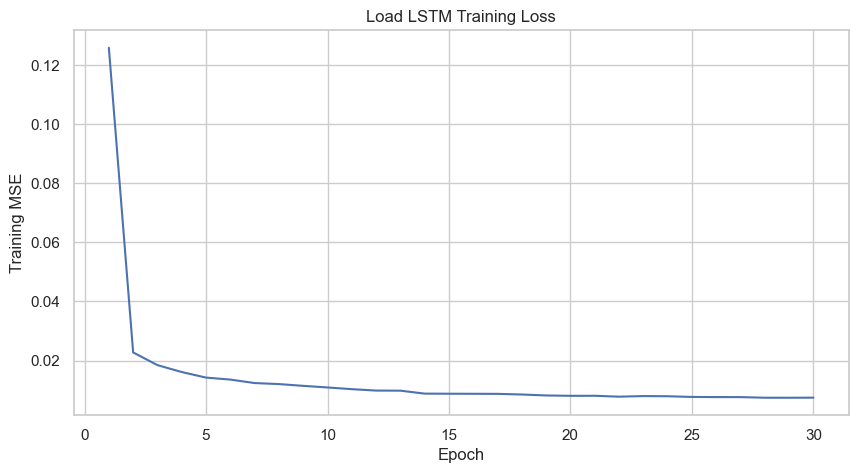

In [ ]:
# ============================================================
# STEP 10.7 — PLOT TRAINING LOSS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(load_history) + 1),
    load_history
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Load LSTM Training Loss")

plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# STEP 11 — GENERATE LOAD TEST PREDICTIONS
# ============================================================

def predict_model(model, data_loader, device):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)

            output = model(X_batch)

            predictions.extend(
                output.cpu().numpy()
            )

            actuals.extend(
                y_batch.numpy()
            )

    return np.array(predictions), np.array(actuals)


# Generate predictions
load_predictions_scaled, load_actual_scaled = predict_model(
    load_model,
    load_test_loader,
    device
)


print("Prediction shape:", load_predictions_scaled.shape)
print("Actual shape    :", load_actual_scaled.shape)

Prediction shape: (8760,)
Actual shape    : (8760,)


In [ ]:
# ============================================================
# STEP 11.1 — INVERSE TRANSFORM PREDICTIONS
# ============================================================

load_predictions = load_y_scaler.inverse_transform(
    load_predictions_scaled.reshape(-1, 1)
).flatten()

load_actual = load_y_scaler.inverse_transform(
    load_actual_scaled.reshape(-1, 1)
).flatten()


print("Prediction range:")
print(
    load_predictions.min(),
    "to",
    load_predictions.max(),
    "MW"
)

print("\nActual range:")
print(
    load_actual.min(),
    "to",
    load_actual.max(),
    "MW"
)

Prediction range:
37281.81 to 83840.91 MW

Actual range:
38617.902 to 83876.46 MW


In [ ]:
# ============================================================
# STEP 11.2 — LOAD TEST METRICS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

load_mae = mean_absolute_error(
    load_actual,
    load_predictions
)

load_rmse = np.sqrt(
    mean_squared_error(
        load_actual,
        load_predictions
    )
)

load_r2 = r2_score(
    load_actual,
    load_predictions
)


print("=" * 50)
print("LOAD LSTM — 2025 TEST RESULTS")
print("=" * 50)

print(f"MAE  : {load_mae:.4f} MW")
print(f"RMSE : {load_rmse:.4f} MW")
print(f"R²   : {load_r2:.4f}")

LOAD LSTM — 2025 TEST RESULTS
MAE  : 619.3125 MW
RMSE : 814.2667 MW
R²   : 0.9935


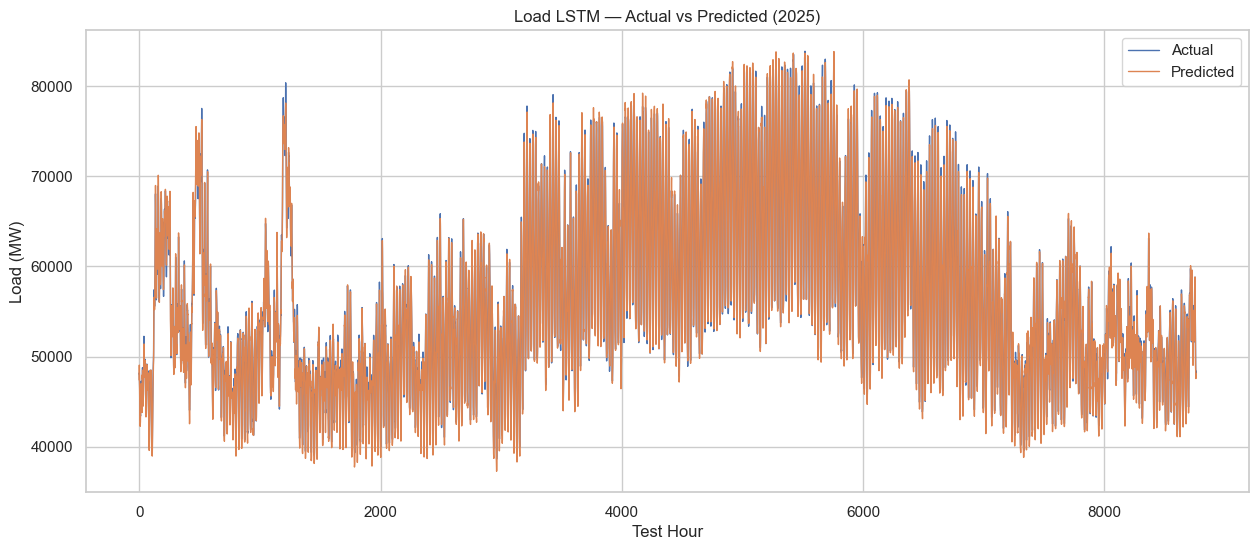

In [ ]:
# ============================================================
# STEP 12 — ACTUAL VS PREDICTED LOAD
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    load_actual,
    label="Actual",
    linewidth=1
)

plt.plot(
    load_predictions,
    label="Predicted",
    linewidth=1
)

plt.xlabel("Test Hour")
plt.ylabel("Load (MW)")
plt.title("Load LSTM — Actual vs Predicted (2025)")
plt.legend()
plt.grid(True)

plt.show()

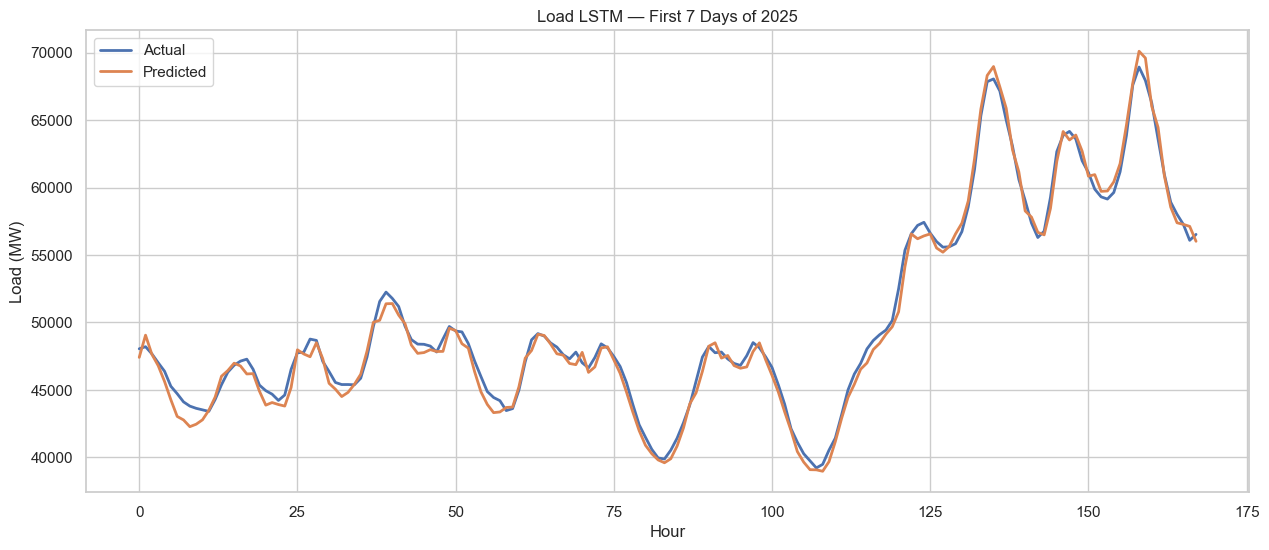

In [ ]:
# ============================================================
# STEP 12.1 — FIRST 7 DAYS
# ============================================================

hours_to_plot = 24 * 7

plt.figure(figsize=(15, 6))

plt.plot(
    load_actual[:hours_to_plot],
    label="Actual",
    linewidth=2
)

plt.plot(
    load_predictions[:hours_to_plot],
    label="Predicted",
    linewidth=2
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load LSTM — First 7 Days of 2025")
plt.legend()
plt.grid(True)

plt.show()

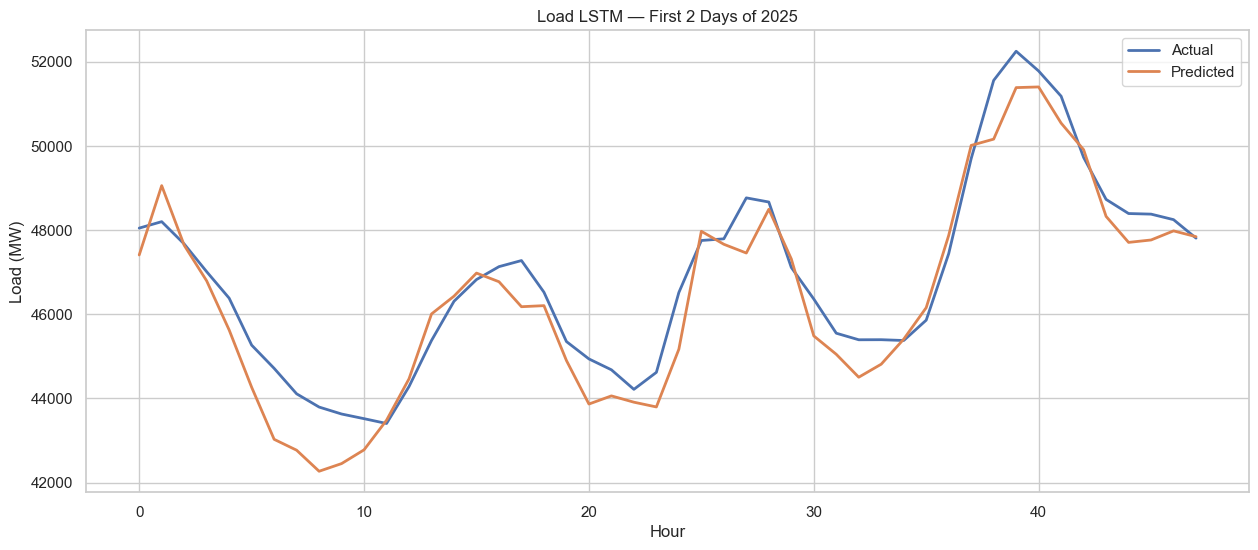

In [ ]:
# ============================================================
# STEP 12.2 — FIRST 2 DAYS OF 2025
# ============================================================

hours_to_plot = 24 * 2

plt.figure(figsize=(15, 6))

plt.plot(
    load_actual[:hours_to_plot],
    label="Actual",
    linewidth=2
)

plt.plot(
    load_predictions[:hours_to_plot],
    label="Predicted",
    linewidth=2
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load LSTM — First 2 Days of 2025")
plt.legend()
plt.grid(True)

plt.show()